IMPORT LIBRARY

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import glob
import os
from statsmodels.tsa.arima.model import ARIMA
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor
from tqdm import tqdm 
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping

PENGOLAHAN DATA 1 MINGGU (11 - 17 JUNI)

PEMBACAAN DATA


In [3]:
df = pd.read_csv('datamentah_bersih.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47116330 entries, 0 to 47116329
Data columns (total 7 columns):
 #   Column          Dtype  
---  ------          -----  
 0   timestamp       object 
 1   bmp388Pressure  float64
 2   sht85Humi       float64
 3   sht85Temp       float64
 4   co2             float64
 5   bawah           float64
 6   atas            float64
dtypes: float64(6), object(1)
memory usage: 2.5+ GB


In [ ]:
#memilih variabel yang akan digunakan
df = df.iloc[:, [0,1,4,5,6,13,14]]

In [25]:
df.head()

,timestamp,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas
0,2024-06-10 00:06:01.353,77.561432,93.356224,25.859844,457.0,0.000000,0.0
1,2024-06-10 00:06:01.436,99.107700,93.426414,25.902569,457.0,0.000000,0.0
2,2024-06-10 00:06:01.598,99.343846,93.461510,25.915920,457.0,0.085611,0.0
3,2024-06-10 00:06:01.760,99.603837,93.488976,25.945299,457.0,0.042186,0.0
4,2024-06-10 00:06:01.922,99.081823,93.429466,25.915920,457.0,0.000000,0.0


Preprocessing Data


In [6]:
flux_c02 = df.copy()
print (flux_c02)

                         bmp388Pressure  sht85Humi  sht85Temp    co2  \
timestamp                                                              
2024-06-10 00:06:01.353       79.026558  93.356224  25.859844  457.0   
2024-06-10 00:06:01.436      101.007477  93.426414  25.902569  457.0   
2024-06-10 00:06:01.598      101.008644  93.461510  25.915920  457.0   
2024-06-10 00:06:01.760      101.008423  93.488976  25.945299  457.0   
2024-06-10 00:06:01.922      101.007614  93.429466  25.915920  457.0   
...                                 ...        ...        ...    ...   
2024-12-28 23:36:00.342       98.708946  90.746785  23.349737  481.0   
2024-12-28 23:36:00.505       98.706985  90.945979  23.424505  481.0   
2024-12-28 23:36:00.666       98.704842  90.781978  23.408484  481.0   
2024-12-28 23:36:00.828       98.702774  90.668152  23.381781  481.0   
2024-12-28 23:36:00.991       98.701012  90.812406  23.424505  482.0   

                            bawah  atas  
timestamp            

Myesuaikan Tipe Data

In [26]:
# Mengonversi kolom 'timestamp' ke datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# Menjadikan 'timestamp' sebagai indeks
df.set_index('timestamp', inplace=True)

print(df.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 47116330 entries, 2024-06-10 00:06:01.353000 to 2024-12-28 23:36:00.991000
Data columns (total 6 columns):
 #   Column          Dtype  
---  ------          -----  
 0   bmp388Pressure  float64
 1   sht85Humi       float64
 2   sht85Temp       float64
 3   co2             float64
 4   bawah           float64
 5   atas            float64
dtypes: float64(6)
memory usage: 2.5 GB
None


Mencari Missing Value

In [9]:
flux_c02.isnull().sum()

bmp388Pressure    27461717
sht85Humi          4083409
sht85Temp          4083410
co2                      1
bawah              1377569
atas               1377569
dtype: int64

In [10]:
nilai_nol = (flux_c02 == 0).sum()
print (nilai_nol)

bmp388Pressure           0
sht85Humi         10530446
sht85Temp                0
co2                  42517
bawah             42810513
atas              10399714
dtype: int64


VISULISASI DATA SEBELUM PRE-PROCESSING

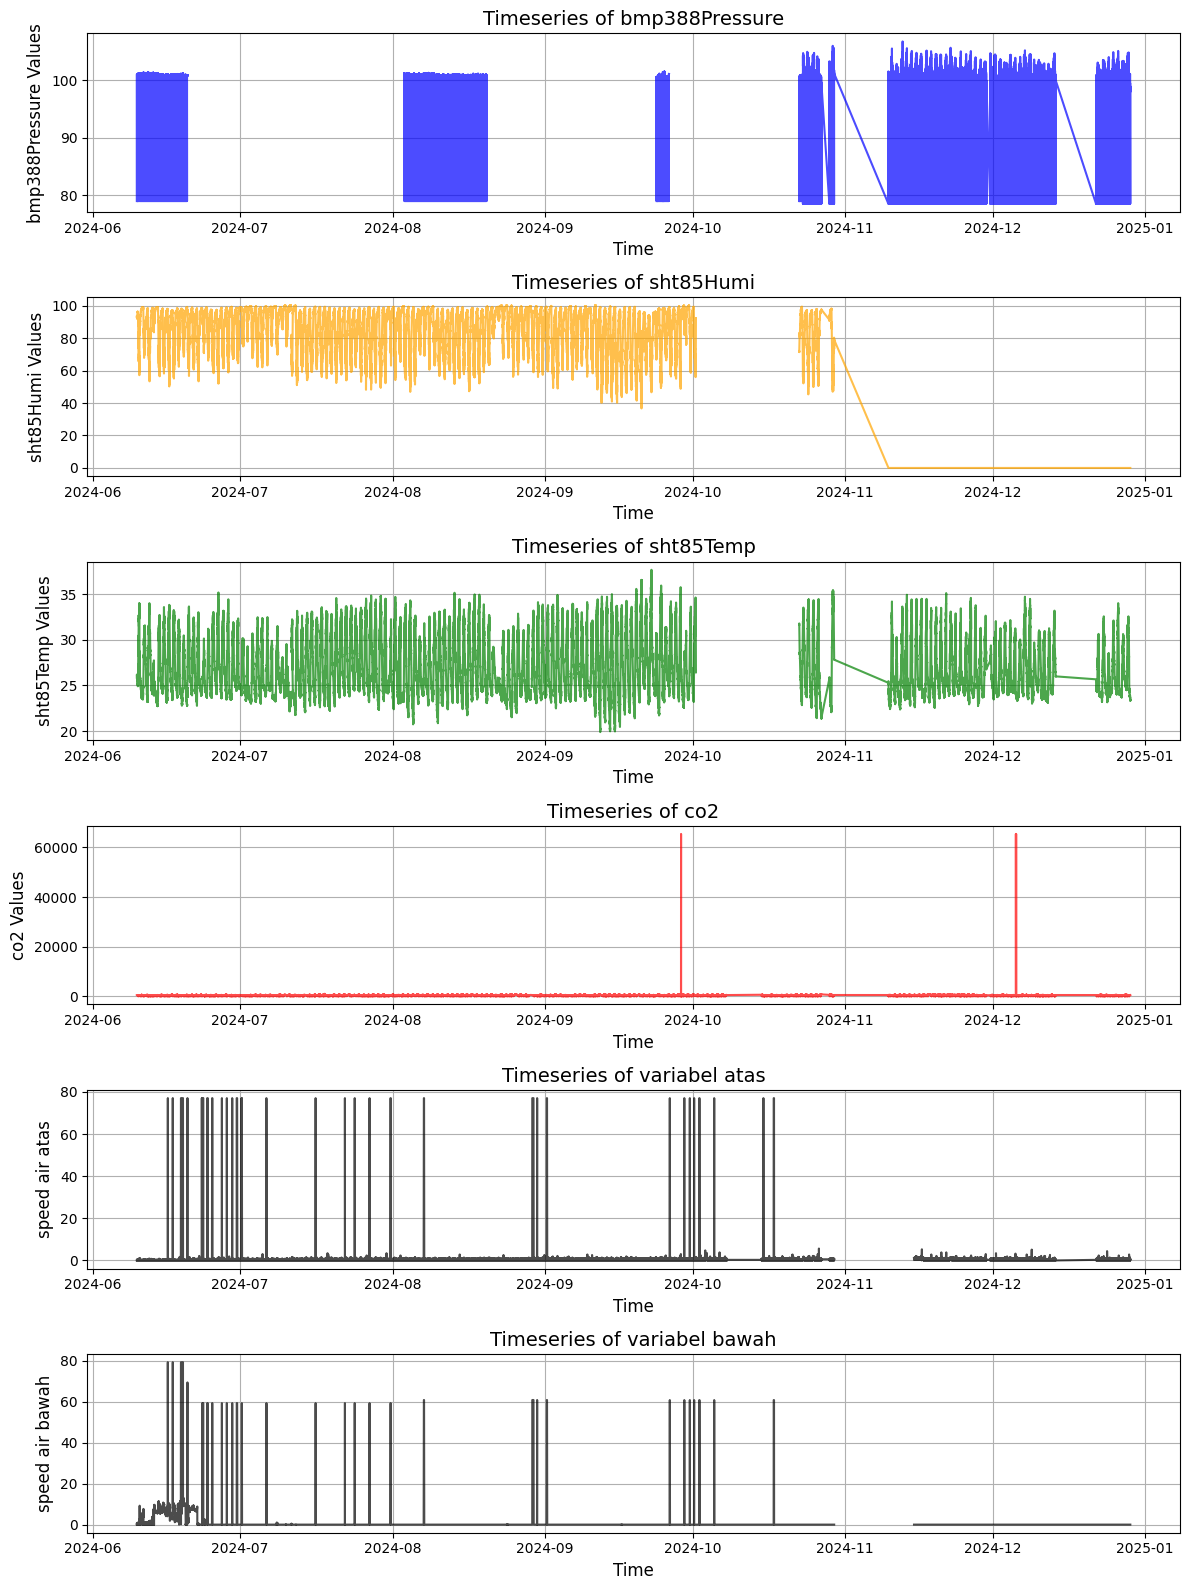

In [12]:
plt.figure(figsize=(12,16))

plt.subplot(6, 1, 1)  # (jumlah baris, jumlah kolom, indeks subplot)
plt.plot(flux_c02.index, flux_c02['bmp388Pressure'], label='bmp388Pressure', color='blue', alpha=0.7)
plt.title('Timeseries of bmp388Pressure', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('bmp388Pressure Values', fontsize=12)
plt.grid(True)


plt.subplot(6, 1, 2)
plt.plot(flux_c02.index, flux_c02['sht85Humi'], label='sht85Humi', color='orange', alpha=0.7)
plt.title('Timeseries of sht85Humi', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('sht85Humi Values', fontsize=12)
plt.grid(True)


plt.subplot(6, 1, 3)
plt.plot(flux_c02.index, flux_c02['sht85Temp'], label='sht85Temp', color='green', alpha=0.7)
plt.title('Timeseries of sht85Temp', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('sht85Temp Values', fontsize=12)
plt.grid(True)


plt.subplot(6, 1, 4)
plt.plot(flux_c02.index, flux_c02['co2'], label='co2', color='r', alpha=0.7)
plt.title('Timeseries of co2', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('co2 Values', fontsize=12)
plt.grid(True)


plt.subplot(6, 1, 5)
plt.plot(flux_c02.index, flux_c02['atas'], label='atas', color='black', alpha=0.7)
plt.title('Timeseries of variabel atas', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air atas', fontsize=12)
plt.grid(True)


plt.subplot(6, 1, 6)
plt.plot(flux_c02.index, flux_c02['bawah'], label='bawah', color='black', alpha=0.7)
plt.title('Timeseries of variabel bawah', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air bawah', fontsize=12)
plt.grid(True)
# Adjust layout for better spacing
plt.tight_layout()

# Tampilkan plot
plt.show()

MENGHILANGKAN OUTLIER

In [7]:
#  Fungsi menangani data hilang pendek
def interpolate_short_gaps(series, max_gap):
    is_na = series.isna().astype(int)
    block_id = (is_na.diff() != 0).cumsum() * is_na
    na_lengths = block_id.value_counts()
    short_gaps = na_lengths[na_lengths <= max_gap].index
    short_gap_mask = block_id.isin(short_gaps)
    
    # Hanya interpolasi yang short gap
    result = series.copy()
    result[short_gap_mask] = result.interpolate(method='linear')[short_gap_mask]
    return result

In [9]:
#Data hilang pendek atas bawah
#  Ganti semua nilai > 20 dengan NaN
flux_c02[['bawah', 'atas']] = flux_c02[['bawah', 'atas']].mask(flux_c02[['bawah', 'atas']] > 20)

#  Parameter batas gap pendek (10 detik = 60 data @6Hz)
MAX_SHORT_GAP = 60

#  Terapkan ke masing-masing kolom
flux_c02['bawah'] = interpolate_short_gaps(flux_c02['bawah'], MAX_SHORT_GAP)
flux_c02['atas'] = interpolate_short_gaps(flux_c02['atas'], MAX_SHORT_GAP)

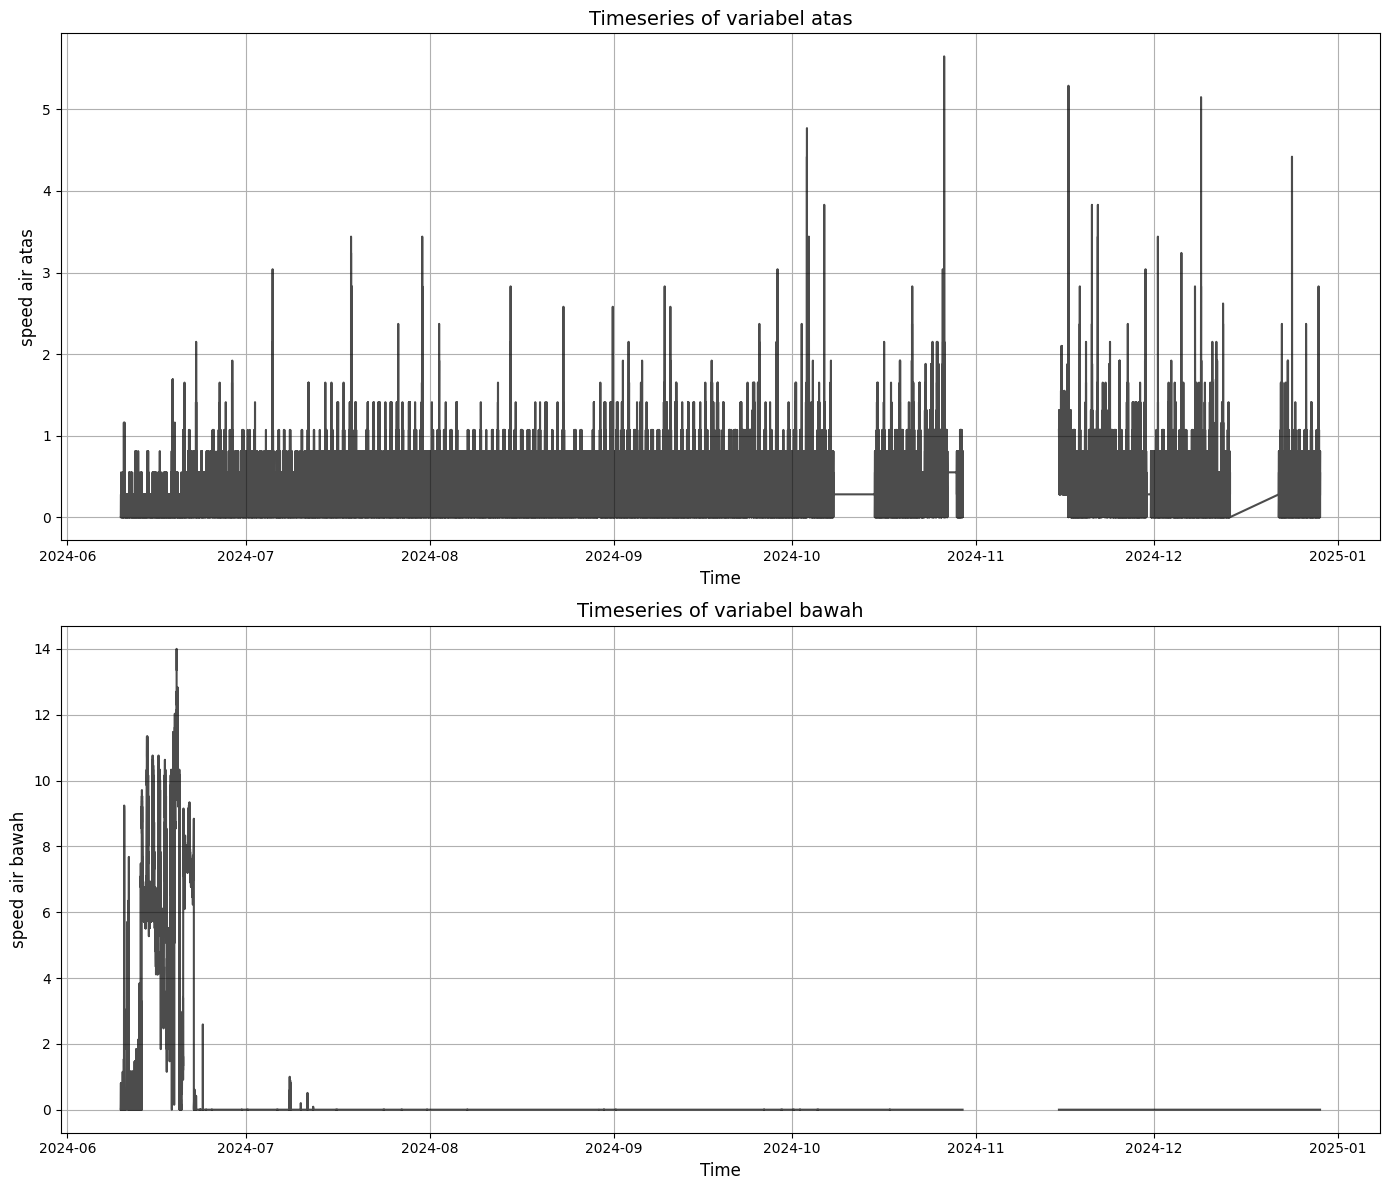

In [10]:

plt.figure(figsize=(14, 12))


plt.subplot(2, 1, 1)
plt.plot(flux_c02.index, flux_c02['atas'], label='atas', color='black', alpha=0.7)
plt.title('Timeseries of variabel atas', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air atas', fontsize=12)
plt.grid(True)


plt.subplot(2, 1, 2)
plt.plot(flux_c02.index, flux_c02['bawah'], label='bawah', color='black', alpha=0.7)
plt.title('Timeseries of variabel bawah', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air bawah', fontsize=12)
plt.grid(True)
# Adjust layout for better spacing
plt.tight_layout()

# Tampilkan plot
plt.show()

In [33]:

# Tambahkan kolom waktu pecah untuk grouping musiman
df['jam'] = df.index.hour
df['menit'] = df.index.minute
df['detik'] = df.index.second

# Fungsi untuk imputasi musiman
def seasonal_impute(df, column, method='mean'):
    if method == 'mean':
        seasonal_stats = df.groupby(['jam', 'menit', 'detik'])[column].mean()
    elif method == 'median':
        seasonal_stats = df.groupby(['jam', 'menit', 'detik'])[column].median()
    else:
        raise ValueError("Method harus 'mean' atau 'median'")
    
    def fill_value(row):
        if pd.isna(row[column]):
            return seasonal_stats.loc[(row['jam'], row['menit'], row['detik'])]
        else:
            return row[column]
    
    return df.apply(fill_value, axis=1)

'''
# Isi missing untuk kedua kolom
df['atas'] = seasonal_impute(df, 'atas', method='mean')   # bisa ganti ke 'median'
df['bawah'] = seasonal_impute(df, 'bawah', method='mean') # bisa ganti ke 'median'
'''

"\n# Isi missing untuk kedua kolom\ndf['atas'] = seasonal_impute(df, 'atas', method='mean')   # bisa ganti ke 'median'\ndf['bawah'] = seasonal_impute(df, 'bawah', method='mean') # bisa ganti ke 'median'\n"

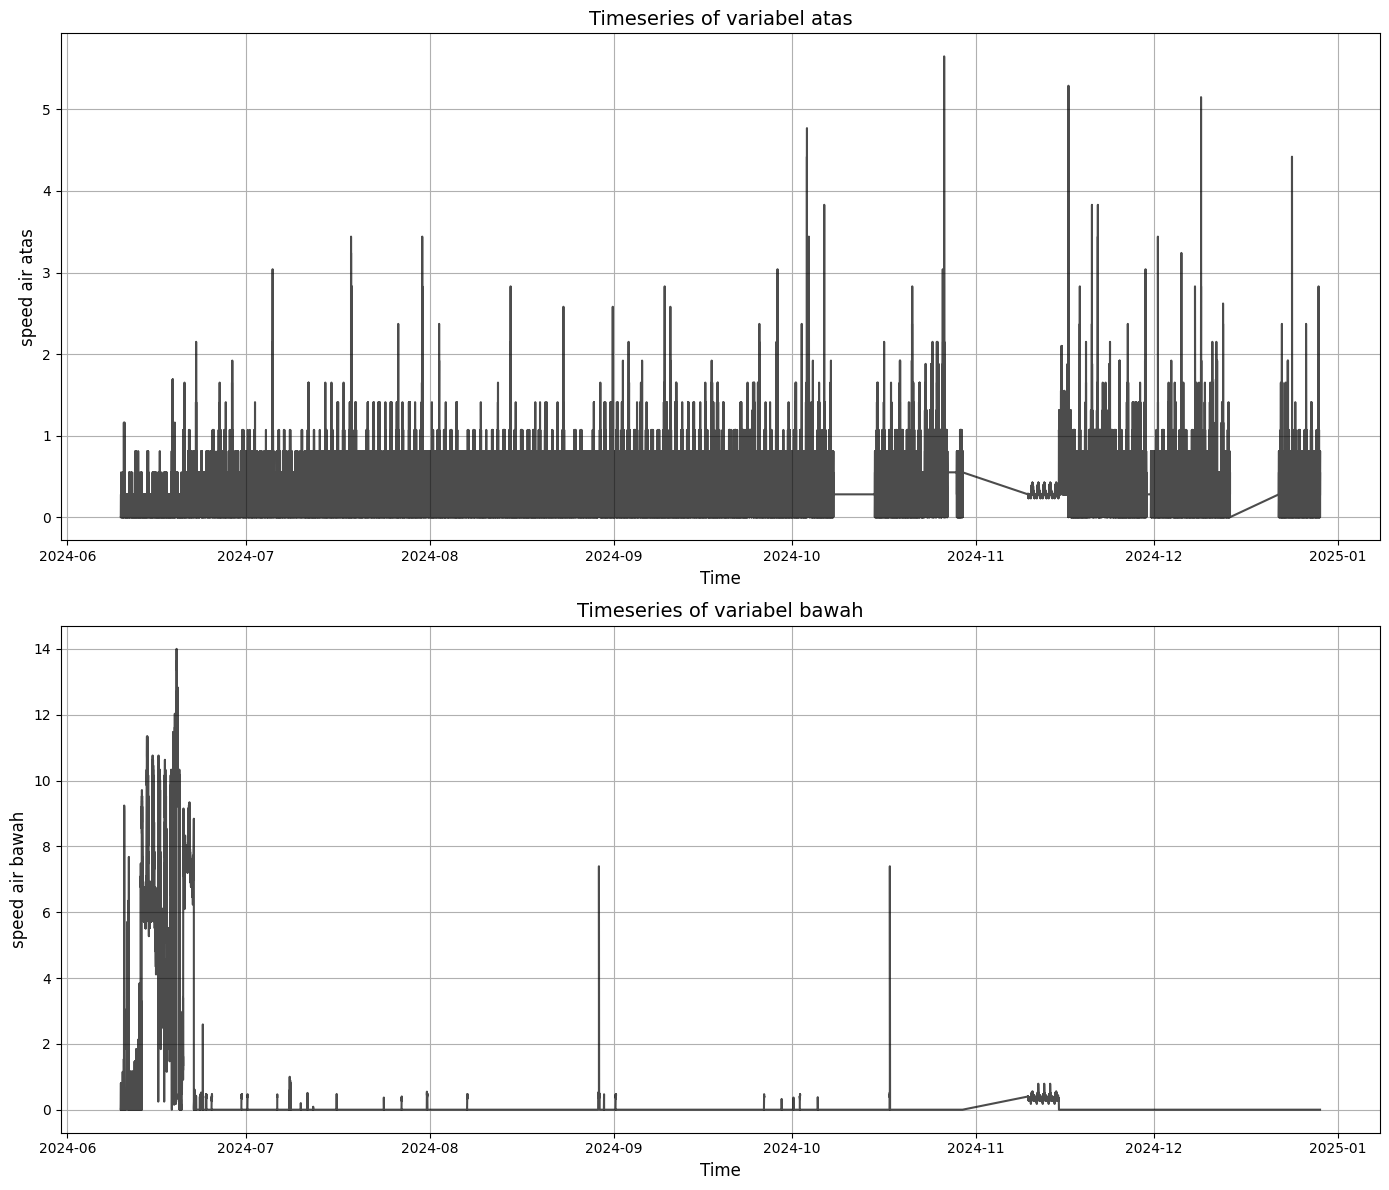

In [ ]:

plt.figure(figsize=(14, 12))


plt.subplot(2, 1, 1)
plt.plot(data_copy.index, data_copy['atas'], label='atas', color='black', alpha=0.7)
plt.title('Timeseries of variabel atas', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air atas', fontsize=12)
plt.grid(True)


plt.subplot(2, 1, 2)
plt.plot(data_copy.index, data_copy['bawah'], label='bawah', color='black', alpha=0.7)
plt.title('Timeseries of variabel bawah', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air bawah', fontsize=12)
plt.grid(True)
# Adjust layout for better spacing
plt.tight_layout()

# Tampilkan plot
plt.show()

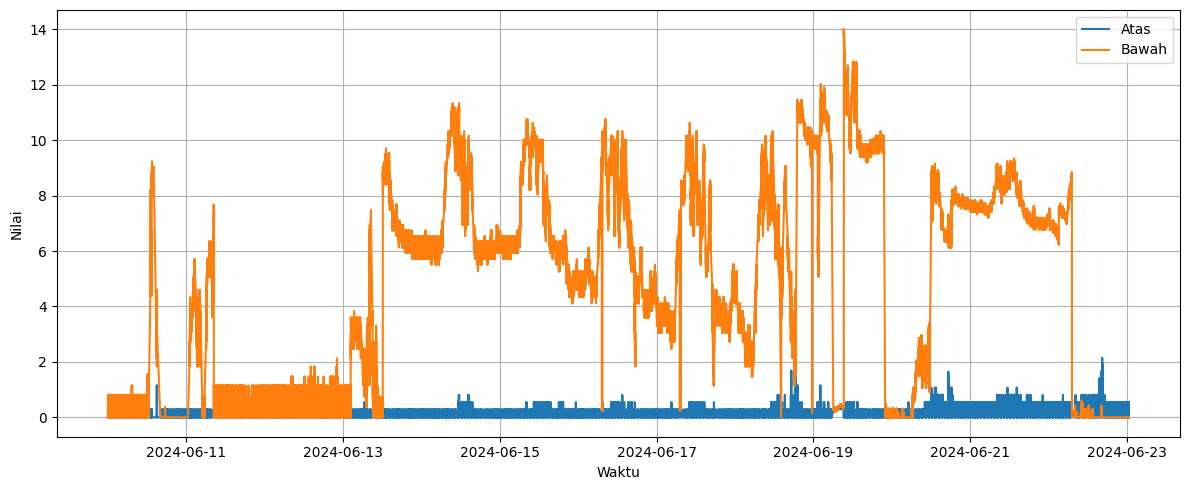

In [26]:
# Filter data
df_range = data_copy.loc['2024-06-10 00:06:01.353':'2024-6-23 01:00:00']

# Plot data
plt.figure(figsize=(12, 5))
plt.plot(df_range.index, df_range['atas'], label='Atas')
plt.plot(df_range.index, df_range['bawah'], label='Bawah')
plt.xlabel('Waktu')
plt.ylabel('Nilai')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# 1. Pisahkan data sebelum 23 Juni
tanggal_cutoff = pd.Timestamp('2024-06-23')
df_before = data_copy[data_copy.index < tanggal_cutoff]

# 2. Tambahkan kolom jam, menit, detik untuk grouping
df_before['jam'] = df_before.index.hour
df_before['menit'] = df_before.index.minute
df_before['detik'] = df_before.index.second

# 3. Hitung median musiman berdasarkan jam, menit, detik
seasonal_median = df_before.groupby(['jam', 'menit', 'detik'])['bawah'].median()

# 4. Tambahkan jam, menit, detik ke seluruh data (data_copy)
data_copy['jam'] = data_copy.index.hour
data_copy['menit'] = data_copy.index.minute
data_copy['detik'] = data_copy.index.second

# 5. Untuk data setelah 23 Juni, ganti nilai 'bawah' dengan seasonal median
mask = data_copy.index >= tanggal_cutoff
keys = list(zip(data_copy.loc[mask, 'jam'], data_copy.loc[mask, 'menit'], data_copy.loc[mask, 'detik']))
replacement_values = [seasonal_median.get(k, np.nan) for k in keys]
data_copy.loc[mask, 'bawah'] = replacement_values

# 6. (Opsional) Hapus kolom tambahan
data_copy.drop(columns=['jam', 'menit', 'detik'], inplace=True)


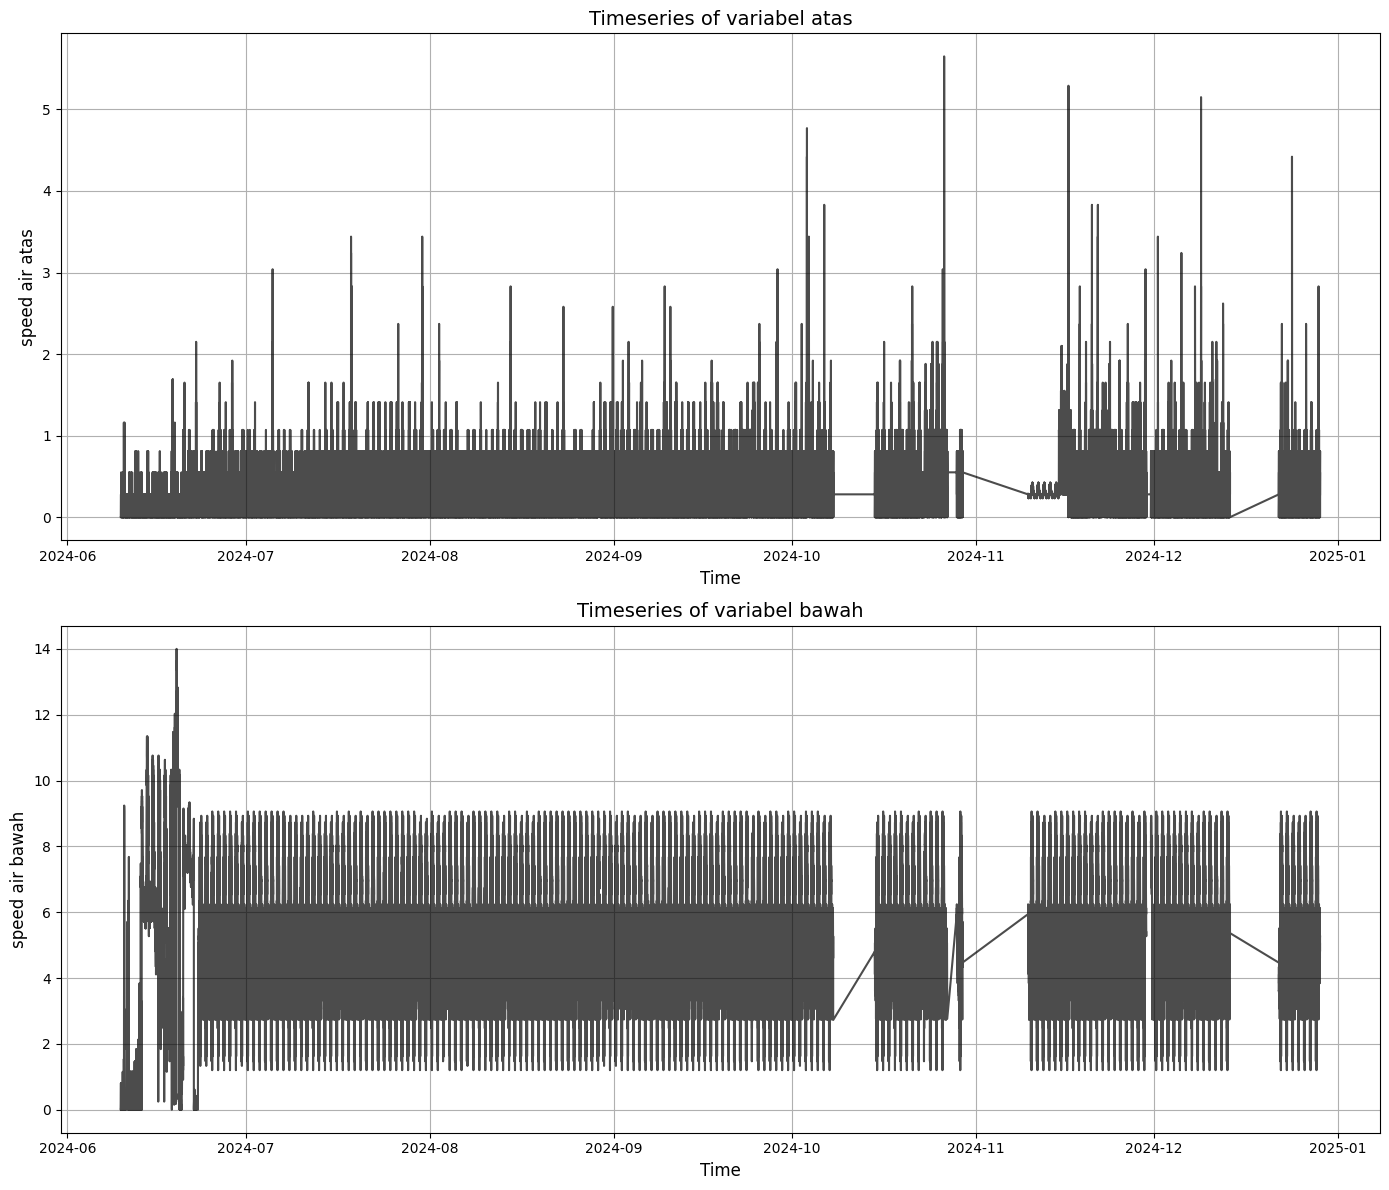

In [28]:

plt.figure(figsize=(14, 12))


plt.subplot(2, 1, 1)
plt.plot(data_copy.index, data_copy['atas'], label='atas', color='black', alpha=0.7)
plt.title('Timeseries of variabel atas', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air atas', fontsize=12)
plt.grid(True)


plt.subplot(2, 1, 2)
plt.plot(data_copy.index, data_copy['bawah'], label='bawah', color='black', alpha=0.7)
plt.title('Timeseries of variabel bawah', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air bawah', fontsize=12)
plt.grid(True)
# Adjust layout for better spacing
plt.tight_layout()

# Tampilkan plot
plt.show()

C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


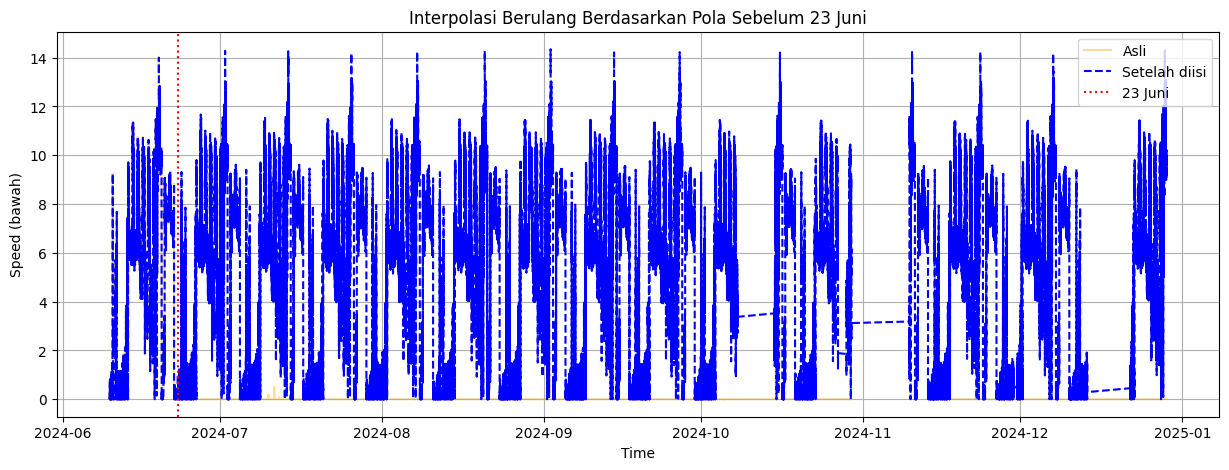

In [34]:
# Ambil data sebelum 23 Juni sebagai pola
cutoff = pd.Timestamp("2024-06-23")
pattern = data_copy[data_copy.index < cutoff]

# Ambil data sesudah cutoff yang ingin diisi
after_cutoff = data_copy[data_copy.index >= cutoff]
missing_dates = after_cutoff.index

# Cek apakah pattern tersedia
if len(pattern) == 0 or len(missing_dates) == 0:
    print("Pattern kosong atau tidak ada data setelah cutoff.")
else:
    # Perbanyak pattern hingga panjangnya sama
    repeat_count = int(np.ceil(len(missing_dates) / len(pattern)))
    repeated_pattern = np.tile(pattern['bawah'].values, repeat_count)[:len(missing_dates)]

    # Tambahkan noise
    noise = np.random.normal(0, 0.1, size=len(missing_dates))  # ubah skala jika perlu
    filled_values = np.clip(repeated_pattern + noise, a_min=0, a_max=None)

    # Buat dataframe hasil pengisian
    filled_df = pd.DataFrame({'bawah': filled_values}, index=missing_dates)

    # Gabungkan
    df_filled = pd.concat([pattern, filled_df])
    df_filled = df_filled.sort_index()

    # Plot hasilnya
    plt.figure(figsize=(15, 5))
    plt.plot(data_copy.index, data_copy['bawah'], color='orange', alpha=0.4, label='Asli')
    plt.plot(df_filled.index, df_filled['bawah'], color='blue', linestyle='--', label='Setelah diisi')
    plt.axvline(cutoff, color='red', linestyle=':', label='23 Juni')
    plt.title("Interpolasi Berulang Berdasarkan Pola Sebelum 23 Juni")
    plt.xlabel("Time")
    plt.ylabel("Speed (bawah)")
    plt.legend()
    plt.grid(True)
    plt.show()

In [41]:
# Step 1: Reset index sementara agar tidak error
data_copy_reset = data_copy.reset_index()
filled_df_reset = filled_df.reset_index()

# Step 2: Gabungkan nilai 'bawah' dari filled_df ke data_copy
data_copy_reset['bawah'] = filled_df_reset['bawah']

# Step 3: Kembalikan index semula
data_copy = data_copy_reset.set_index('timestamp')


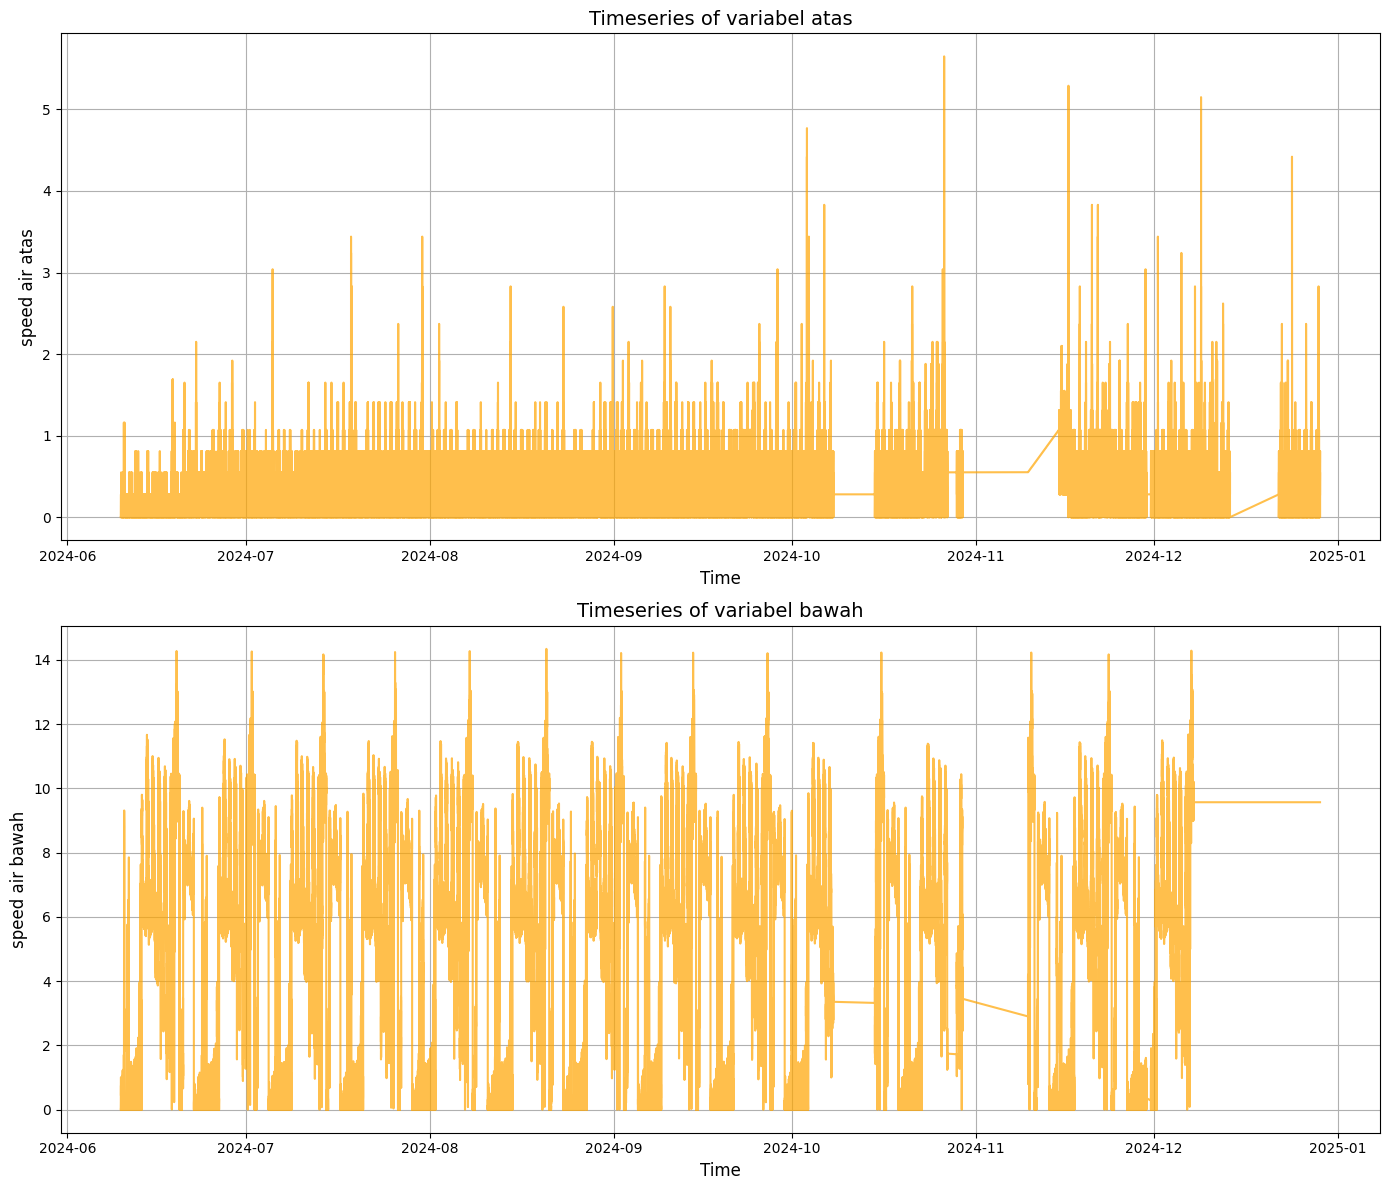

In [51]:
plt.figure(figsize=(14, 12))


plt.subplot(2, 1, 1)
plt.plot(data_copy.index, data_copy['atas'], label='atas', color='orange', alpha=0.7)
plt.title('Timeseries of variabel atas', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air atas', fontsize=12)
plt.grid(True)


plt.subplot(2, 1, 2)
plt.plot(data_copy.index, data_copy['bawah'], label='bawah', color='orange', alpha=0.7)
plt.title('Timeseries of variabel bawah', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air bawah', fontsize=12)
plt.grid(True)
# Adjust layout for better spacing
plt.tight_layout()

# Tampilkan plot
plt.show()

In [50]:
# Pastikan interpolasi juga bekerja di awal/akhir dengan forward/backward fill jika perlu
data_copy['atas'] = data_copy['atas'].interpolate(method='linear').ffill().bfill()
data_copy['bawah'] = data_copy['bawah'].interpolate(method='linear').ffill().bfill()


In [56]:

flux_c02['atas'] = data_copy['atas']
flux_c02['bawah'] = data_copy['bawah']


CO2

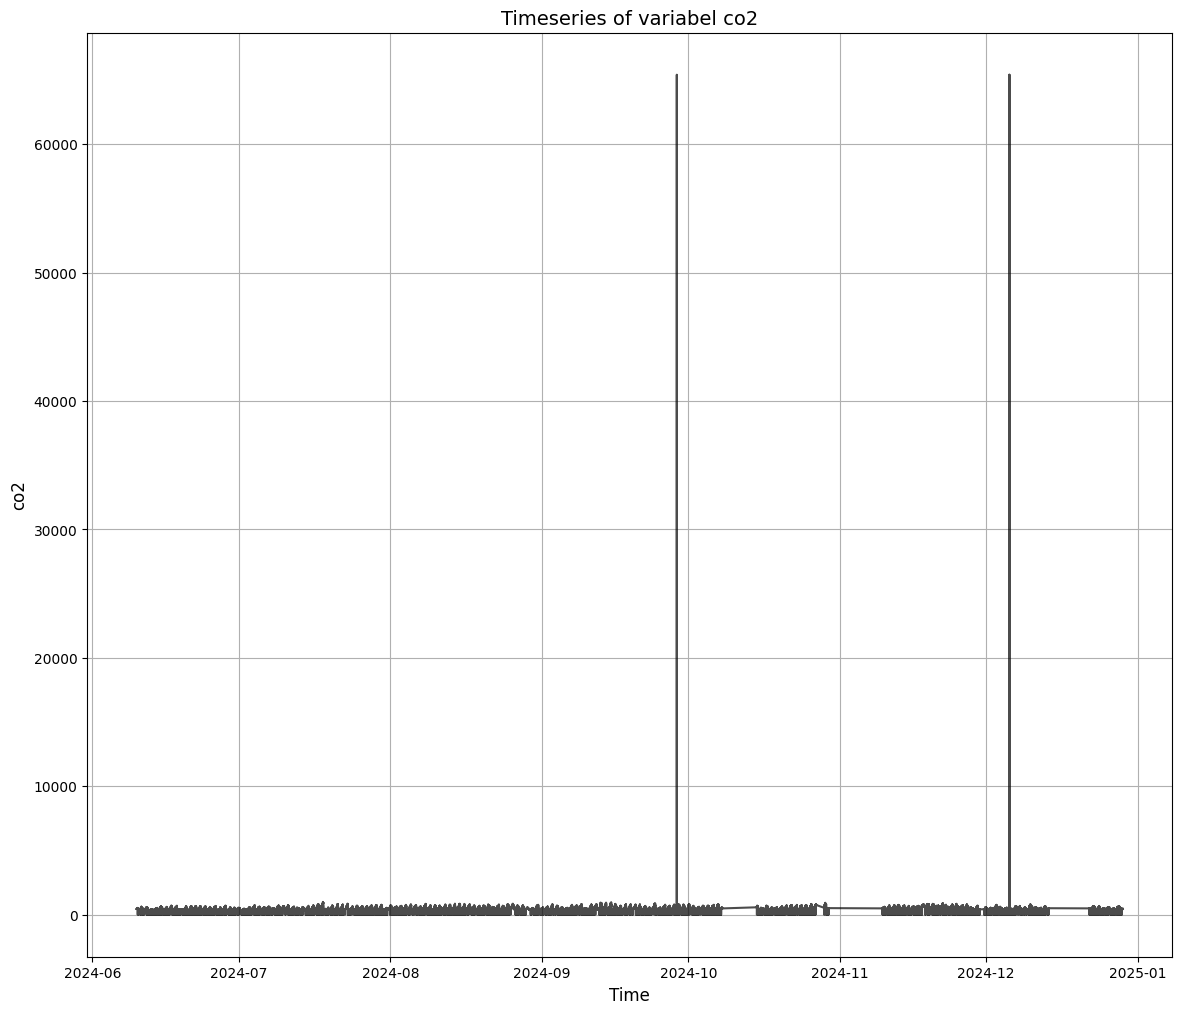

In [57]:
#visualisasi sebelum pre-processing
plt.figure(figsize=(14, 12))

plt.plot(flux_c02.index, flux_c02['co2'], label='co2', color='black', alpha=0.7)
plt.title('Timeseries of variabel co2', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('co2', fontsize=12)
plt.grid(True)

In [67]:
# Ubah nilai 0 menjadi NaN di kolom 'co2'
flux_c02['co2'] = flux_c02['co2'].replace(0, np.nan)

# Ubah nilai CO2 > 5000 menjadi NaN
flux_c02.loc[flux_c02['co2'] > 1100, 'co2'] = np.nan

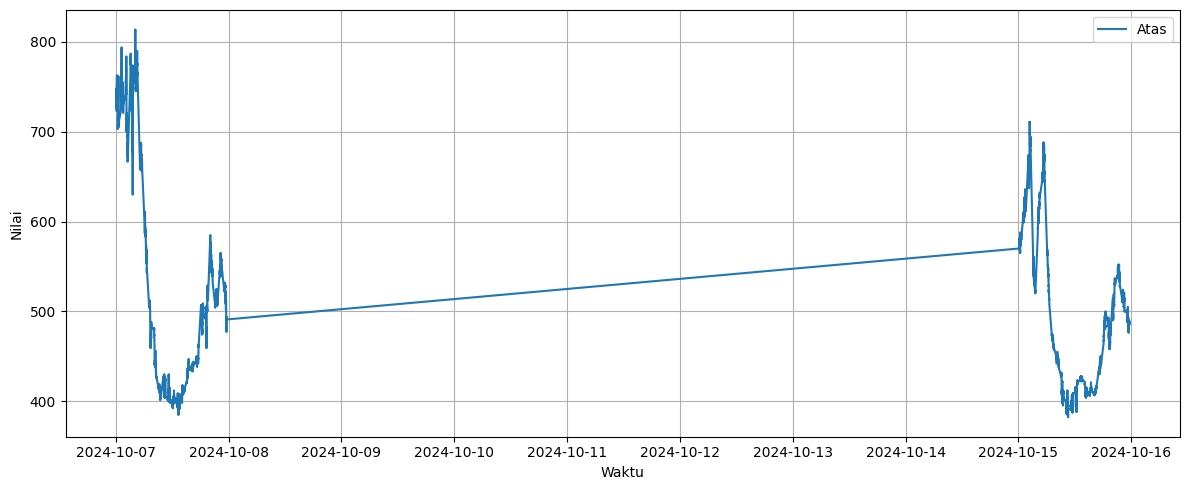

In [102]:
# Filter data
df_range = flux_c02.loc['2024-10-07':'2024-10-15']

# Plot data
plt.figure(figsize=(12, 5))
plt.plot(df_range.index, df_range['co2'], label='Atas')

plt.xlabel('Waktu')
plt.ylabel('Nilai')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [105]:
# Pastikan index dalam datetime
flux_c02.index = pd.to_datetime(flux_c02.index)

# Tentukan rentang waktu
start_time = '2024-10-8'
end_time = '2024-10-15'

# Ganti nilai dalam rentang itu jadi NaN
flux_c02.loc[start_time:end_time, 'co2'] = np.nan

In [79]:
flux_c02['co2'] = interpolate_short_gaps(flux_c02['co2'], MAX_SHORT_GAP)

In [110]:
flux_c02['co2'] = flux_c02['co2'].interpolate(method='time')

C:\Users\USER\AppData\Local\Temp\ipykernel_22760\3383864453.py:16: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


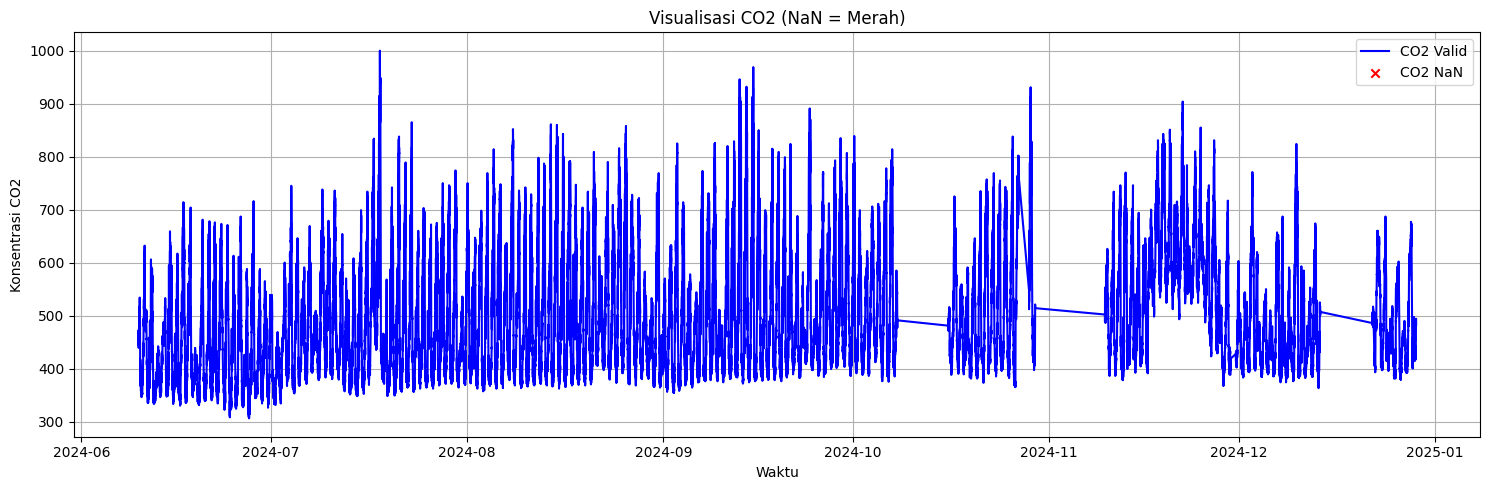

In [111]:


# Buat mask untuk nilai NaN dan bukan NaN
co2 = flux_c02['co2']
not_nan = co2.notna()
is_nan = co2.isna()

# Plot nilai CO2
plt.figure(figsize=(15, 5))
plt.plot(flux_c02.index[not_nan], co2[not_nan], label='CO2 Valid', color='blue')
plt.scatter(flux_c02.index[is_nan], [0]*is_nan.sum(), label='CO2 NaN', color='red', marker='x')

plt.title('Visualisasi CO2 (NaN = Merah)')
plt.xlabel('Waktu')
plt.ylabel('Konsentrasi CO2')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Kelembaban

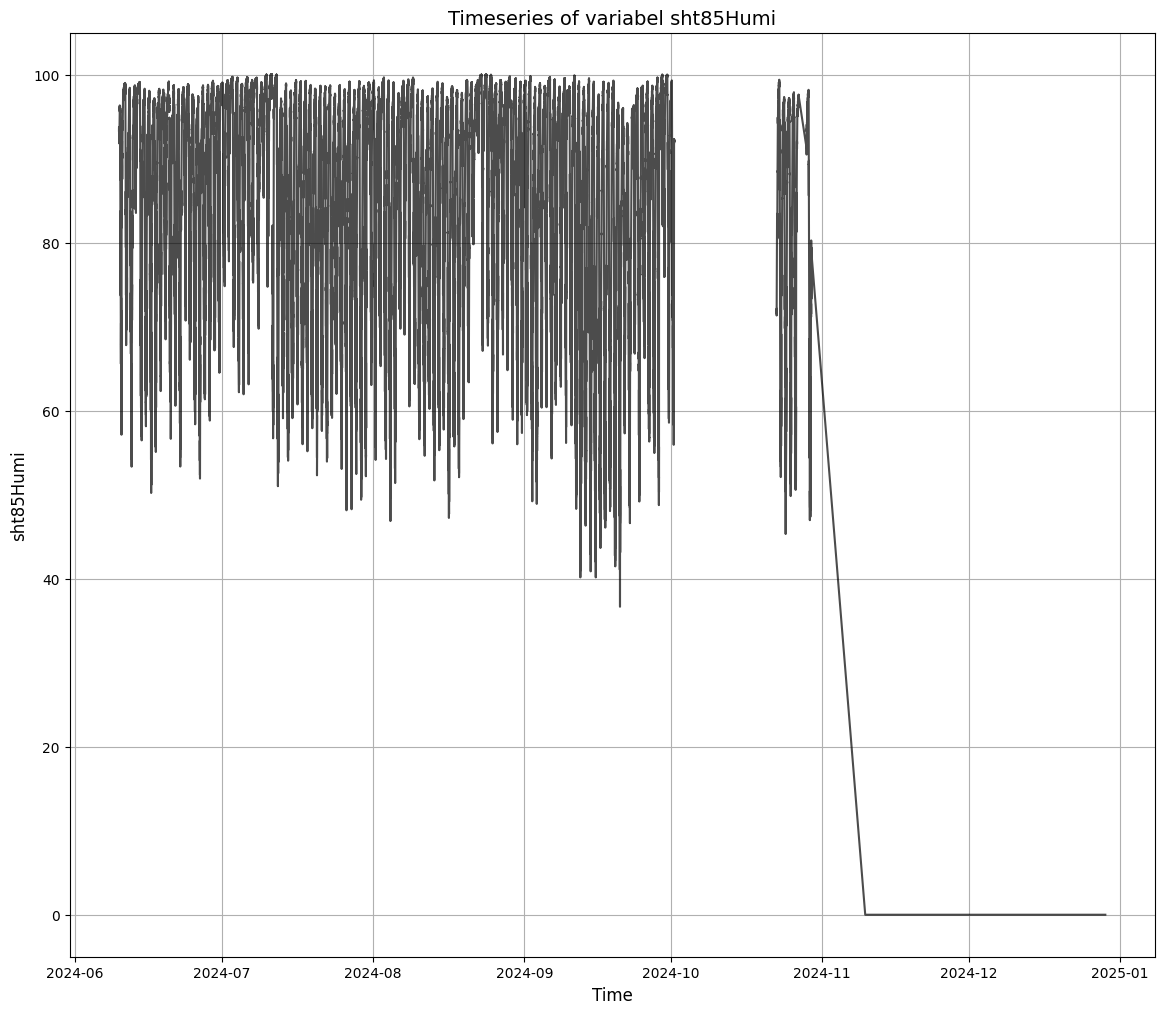

In [112]:
#visualisasi sebelum pre-processing
plt.figure(figsize=(14, 12))

plt.plot(flux_c02.index, flux_c02['sht85Humi'], label='sht85Humi', color='black', alpha=0.7)
plt.title('Timeseries of variabel sht85Humi', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('sht85Humi', fontsize=12)
plt.grid(True)

In [138]:
data_copy = flux_c02.copy()

In [139]:
# Ubah nilai co2 menjadi NaN dari November 2024 ke depan
data_copy.loc[data_copy.index >= '2024-10-01', 'sht85Humi'] = np.nan

In [125]:
# Interpolasi berbasis waktu
data_copy['sht85Humi'] = data_copy['sht85Humi'].interpolate(method='time')

C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


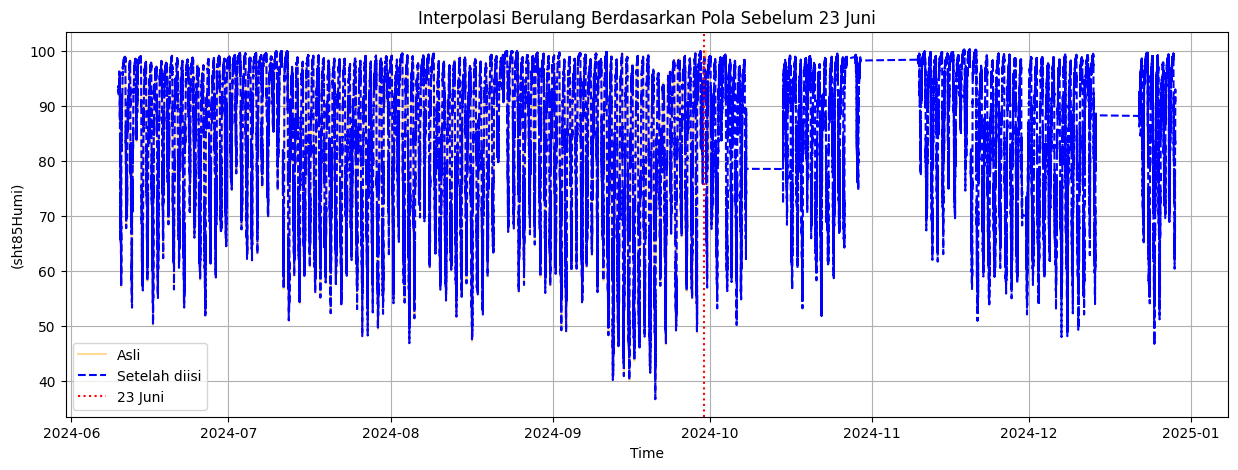

In [141]:
# Ambil data sebelum 23 Juni sebagai pola
cutoff = pd.Timestamp("2024-9-30")
pattern = data_copy[data_copy.index < cutoff]

# Ambil data sesudah cutoff yang ingin diisi
after_cutoff = data_copy[data_copy.index >= cutoff]
missing_dates = after_cutoff.index

# Cek apakah pattern tersedia
if len(pattern) == 0 or len(missing_dates) == 0:
    print("Pattern kosong atau tidak ada data setelah cutoff.")
else:
    # Perbanyak pattern hingga panjangnya sama
    repeat_count = int(np.ceil(len(missing_dates) / len(pattern)))
    repeated_pattern = np.tile(pattern['sht85Humi'].values, repeat_count)[:len(missing_dates)]

    # Tambahkan noise
    noise = np.random.normal(0, 0.1, size=len(missing_dates))  # ubah skala jika perlu
    filled_values = np.clip(repeated_pattern + noise, a_min=0, a_max=None)

    # Buat dataframe hasil pengisian
    filled_df = pd.DataFrame({'sht85Humi': filled_values}, index=missing_dates)

    # Gabungkan
    df_filled = pd.concat([pattern, filled_df])
    df_filled = df_filled.sort_index()

    # Plot hasilnya
    plt.figure(figsize=(15, 5))
    plt.plot(data_copy.index, data_copy['sht85Humi'], color='orange', alpha=0.4, label='Asli')
    plt.plot(df_filled.index, df_filled['sht85Humi'], color='blue', linestyle='--', label='Setelah diisi')
    plt.axvline(cutoff, color='red', linestyle=':', label='23 Juni')
    plt.title("Interpolasi Berulang Berdasarkan Pola Sebelum 23 Juni")
    plt.xlabel("Time")
    plt.ylabel("(sht85Humi)")
    plt.legend()
    plt.grid(True)
    plt.show()

In [133]:
# Step 1: Reset index sementara agar tidak error
data_copy_reset = data_copy.reset_index()
filled_df_reset = filled_df.reset_index()

# Step 2: Gabungkan nilai 'sht85Humi' dari filled_df ke data_copy
data_copy_reset['sht85Humi'] = filled_df_reset['sht85Humi']

# Step 3: Kembalikan index semula
data_copy = data_copy_reset.set_index('timestamp')

In [142]:
flux_c02['sht85Humi'] = df_filled['sht85Humi']

SUHU

In [22]:
flux_c02 = df.copy()

C:\Users\USER\AppData\Local\Temp\ipykernel_9992\2763715216.py:16: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


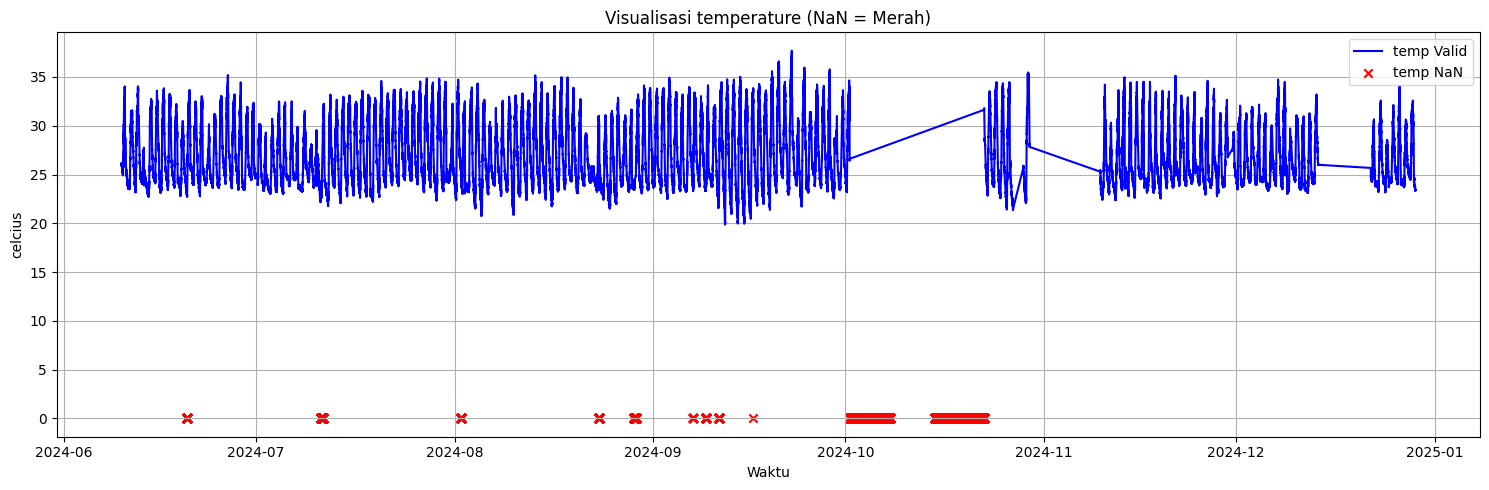

In [16]:
# Buat mask untuk nilai NaN dan bukan NaN
sht85Temp = flux_c02['sht85Temp']
not_nan = sht85Temp.notna()
is_nan = sht85Temp.isna()

# Plot nilai CO2
plt.figure(figsize=(15, 5))
plt.plot(flux_c02.index[not_nan], sht85Temp[not_nan], label='temp Valid', color='blue')
plt.scatter(flux_c02.index[is_nan], [0]*is_nan.sum(), label='temp NaN', color='red', marker='x')

plt.title('Visualisasi temperature (NaN = Merah)')
plt.xlabel('Waktu')
plt.ylabel('celcius')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [24]:
flux_c02['sht85Temp'] = interpolate_short_gaps(flux_c02['sht85Temp'], 60)

C:\Users\USER\AppData\Local\Temp\ipykernel_9992\2763715216.py:16: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


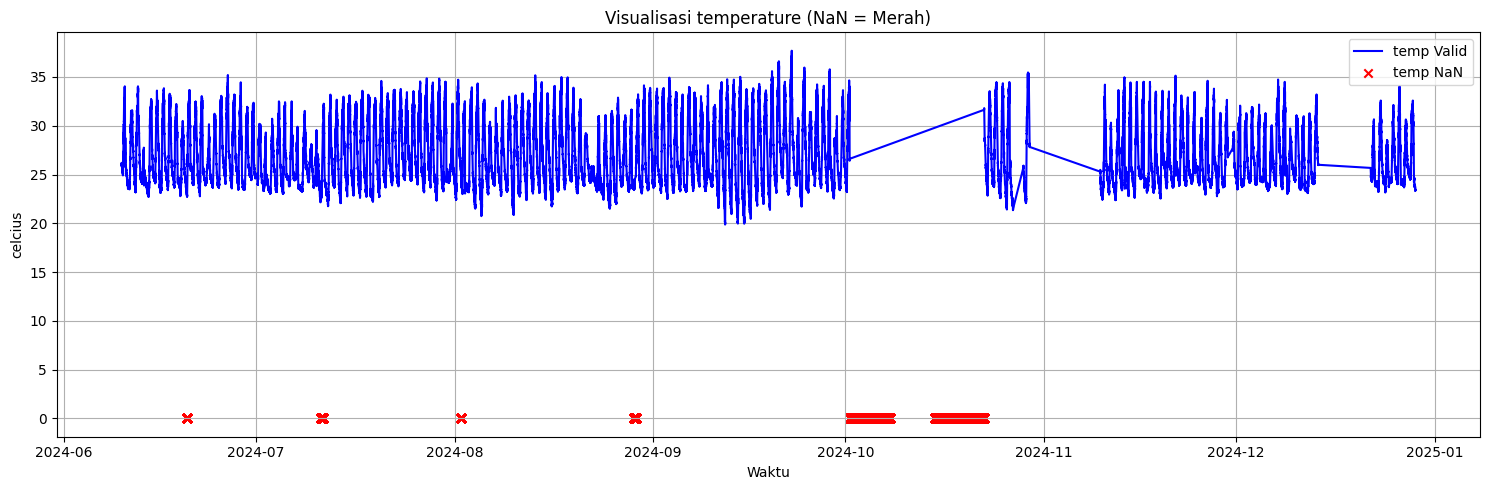

In [18]:
# Buat mask untuk nilai NaN dan bukan NaN
sht85Temp = flux_c02['sht85Temp']
not_nan = sht85Temp.notna()
is_nan = sht85Temp.isna()

# Plot nilai CO2
plt.figure(figsize=(15, 5))
plt.plot(flux_c02.index[not_nan], sht85Temp[not_nan], label='temp Valid', color='blue')
plt.scatter(flux_c02.index[is_nan], [0]*is_nan.sum(), label='temp NaN', color='red', marker='x')

plt.title('Visualisasi temperature (NaN = Merah)')
plt.xlabel('Waktu')
plt.ylabel('celcius')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_9992\1748403298.py:11: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


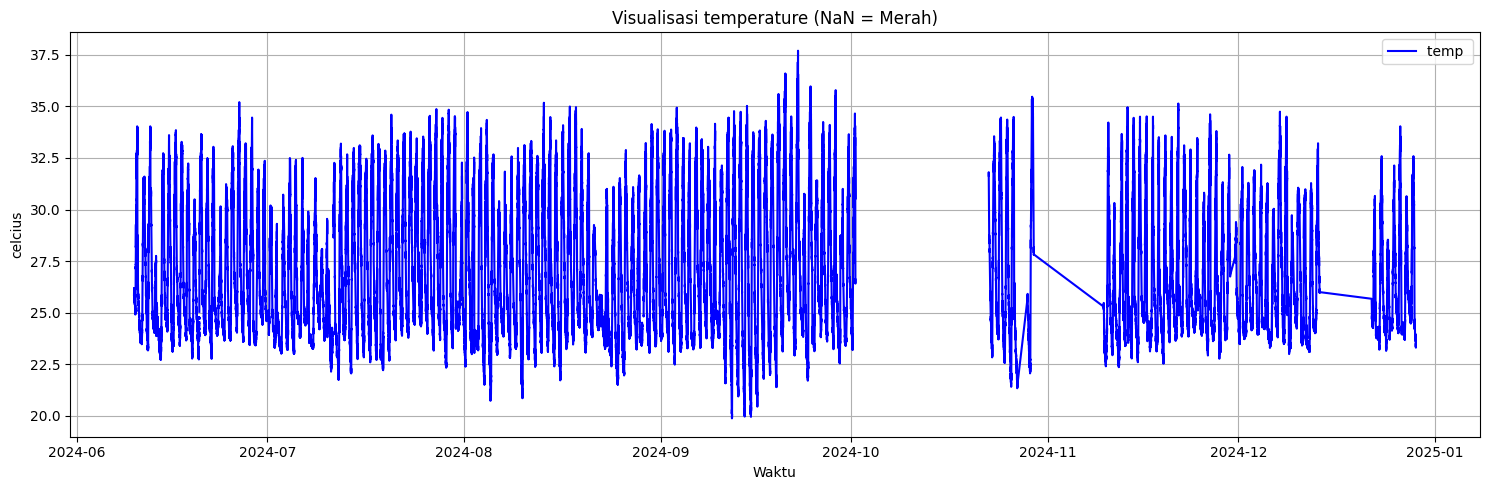

In [25]:
# Plot nilai CO2
plt.figure(figsize=(15, 5))
plt.plot(flux_c02.index, flux_c02['sht85Temp'], label='temp ', color='blue')


plt.title('Visualisasi temperature (NaN = Merah)')
plt.xlabel('Waktu')
plt.ylabel('celcius')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

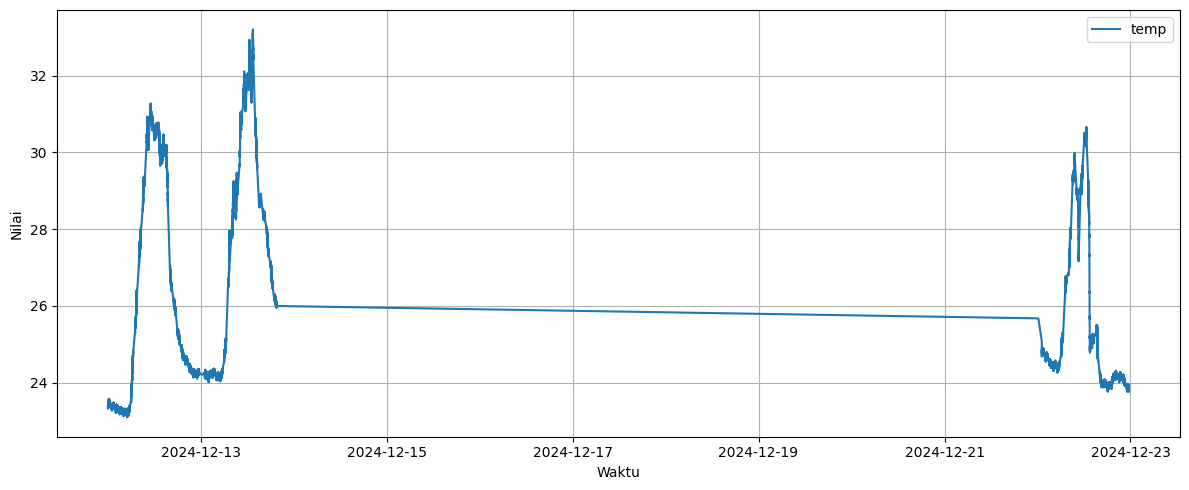

In [37]:
# Filter data
df_range = flux_c02.loc['2024-12-12':'2024-12-22']

# Plot data
plt.figure(figsize=(12, 5))
plt.plot(df_range.index, df_range['sht85Temp'], label='temp')

plt.xlabel('Waktu')
plt.ylabel('Nilai')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [38]:
# Pastikan index dalam datetime
flux_c02.index = pd.to_datetime(flux_c02.index)

# Tentukan rentang waktu
start_time = '2024-12-13'
end_time = '2024-12-22'

# Ganti nilai dalam rentang itu jadi NaN
flux_c02.loc[start_time:end_time, 'sht85Temp'] = np.nan

C:\Users\USER\AppData\Local\Temp\ipykernel_9992\1748403298.py:11: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


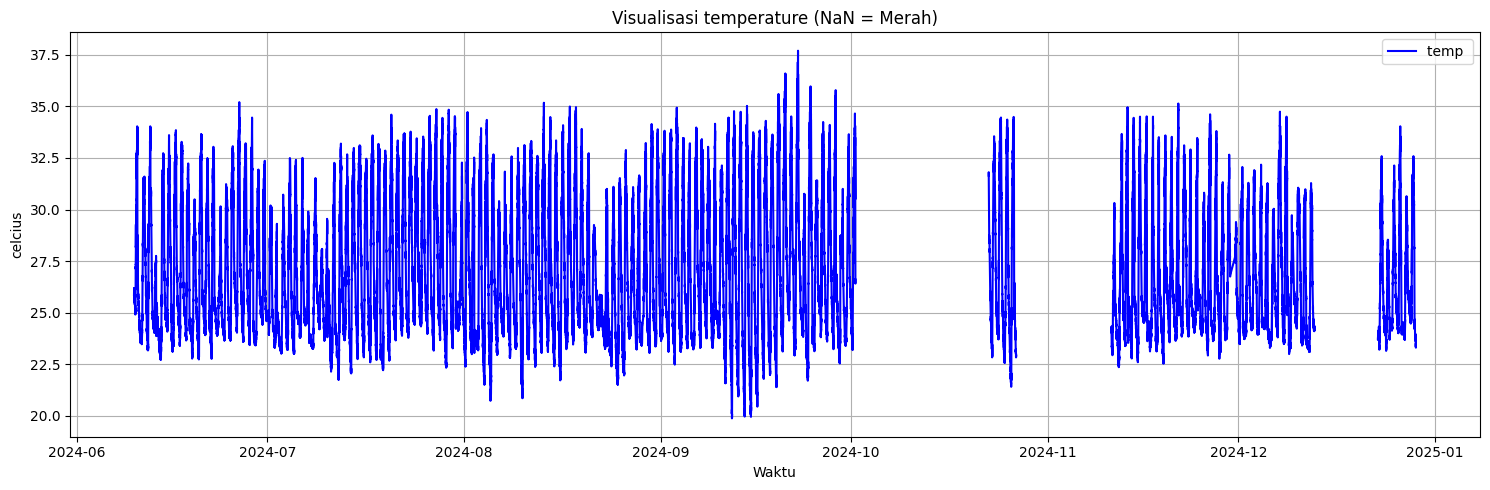

In [53]:
# Plot nilai CO2
plt.figure(figsize=(15, 5))
plt.plot(flux_c02.index, flux_c02['sht85Temp'], label='temp ', color='blue')


plt.title('Visualisasi temperature (NaN = Merah)')
plt.xlabel('Waktu')
plt.ylabel('celcius')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [6]:
# Tambahkan kolom waktu pecah untuk grouping musiman
flux_c02['jam'] = flux_c02.index.hour
flux_c02['menit'] = flux_c02.index.minute
flux_c02['detik'] = flux_c02.index.second

# Fungsi untuk imputasi musiman
def seasonal_impute(flux_c02, column, method='mean'):
    if method == 'mean':
        seasonal_stats = flux_c02.groupby(['jam', 'menit', 'detik'])[column].mean()
    elif method == 'median':
        seasonal_stats = flux_c02.groupby(['jam', 'menit', 'detik'])[column].median()
    else:
        raise ValueError("Method harus 'mean' atau 'median'")
    
    def fill_value(row):
        if pd.isna(row[column]):
            return seasonal_stats.loc[(row['jam'], row['menit'], row['detik'])]
        else:
            return row[column]
    
    return flux_c02.apply(fill_value, axis=1)

# Isi missing untuk kedua kolom
flux_c02['sht85Temp'] = seasonal_impute(flux_c02, 'sht85Temp', method='mean')   # bisa ganti ke 'median'


C:\Users\USER\AppData\Local\Temp\ipykernel_9560\2720110547.py:8: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


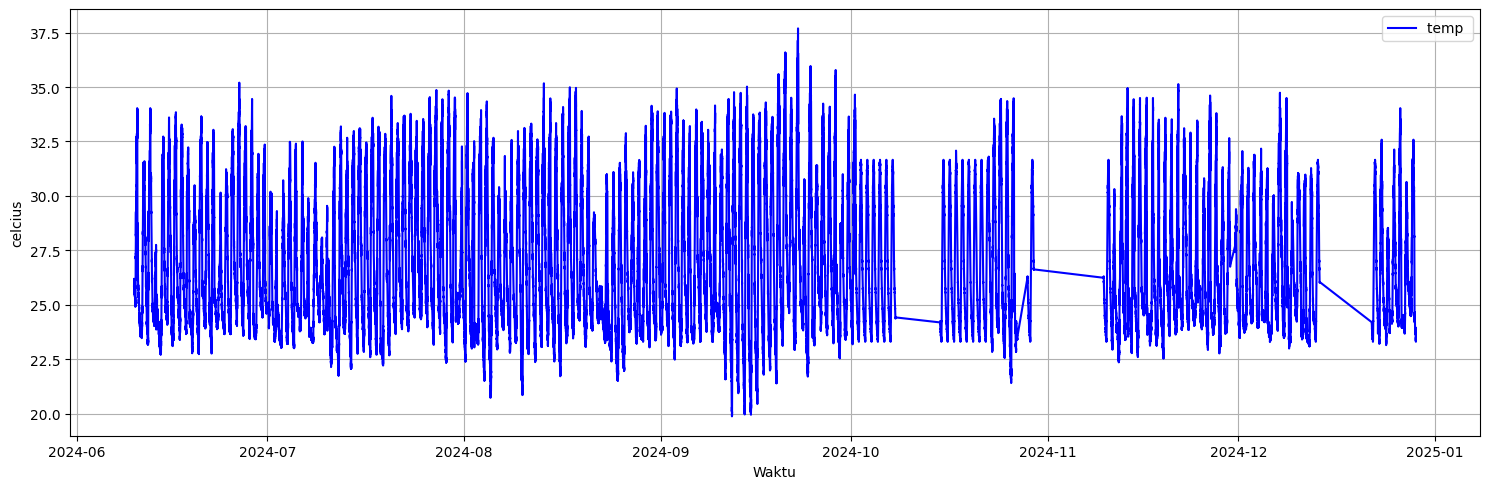

In [ ]:
# Plot niai
plt.figure(figsize=(15, 5))
plt.plot(flux_c02.index, flux_c02['sht85Temp'], label='temp ', color='blue')
plt.xlabel('Waktu')
plt.ylabel('celcius')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Pressure

C:\Users\USER\AppData\Local\Temp\ipykernel_21892\1834154004.py:8: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


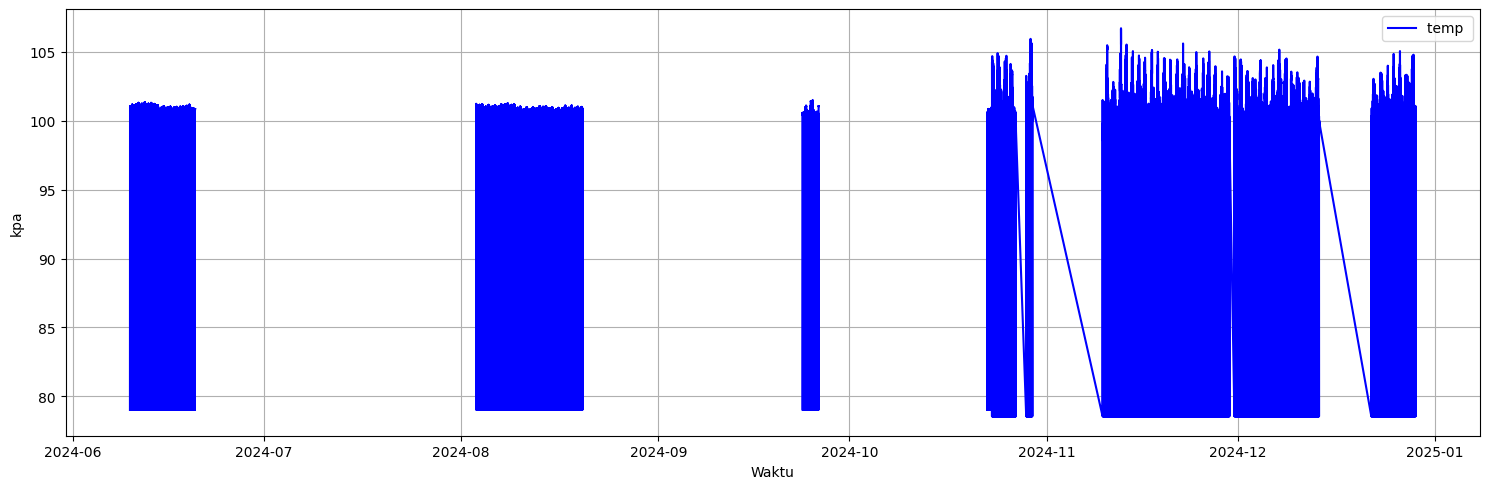

In [8]:
# Plot niai
plt.figure(figsize=(15, 5))
plt.plot(flux_c02.index, flux_c02['bmp388Pressure'], label='temp ', color='blue')
plt.xlabel('Waktu')
plt.ylabel('kpa')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

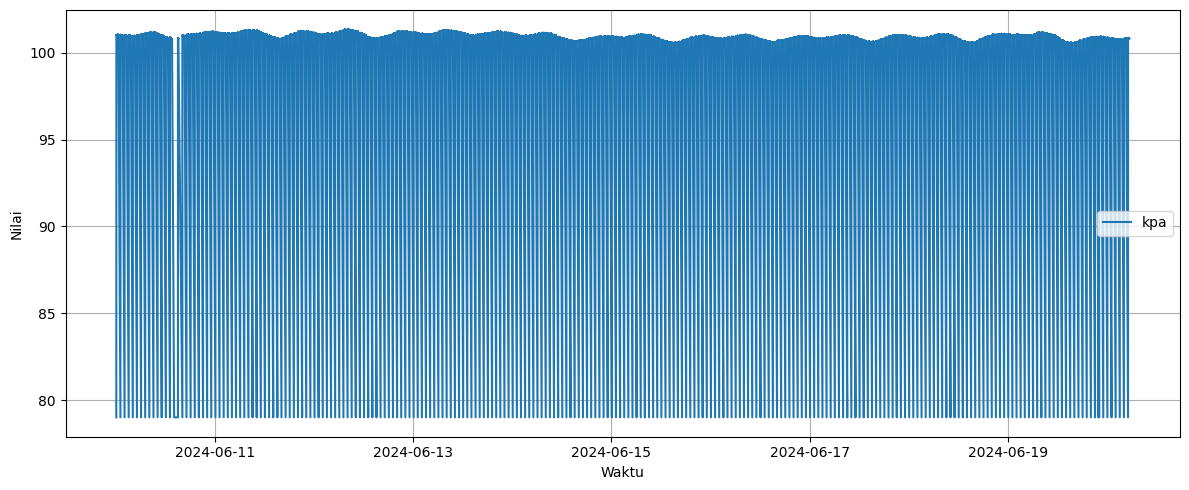

In [18]:
# Filter data
df_range = flux_c02.loc['2024-06-9 00':'2024-06-25 06']

# Plot data
plt.figure(figsize=(12, 5))
plt.plot(df_range.index, df_range['bmp388Pressure'], label='kpa')

plt.xlabel('Waktu')
plt.ylabel('Nilai')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_21892\4219808715.py:27: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


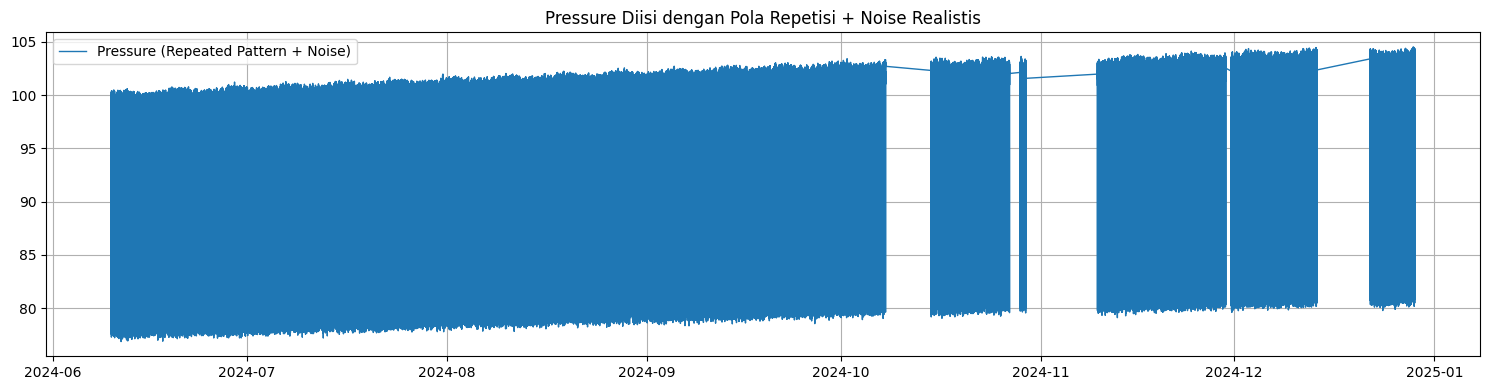

In [9]:
# Ambil pola dari 11–19 Juni
pattern = flux_c02.loc['2024-06-11':'2024-06-19', 'bmp388Pressure'].dropna().values
pattern_len = len(pattern)
total_len = len(flux_c02)

# Perbanyak pola agar sepanjang data
repeated_pattern = np.resize(pattern, total_len)

# Tambahkan noise kecil (sekitar ±0.3% dari nilai)
np.random.seed(42)  # agar hasil reproducible
noise = np.random.normal(loc=0, scale=0.003, size=total_len)
repeated_with_noise = repeated_pattern * (1 + noise)

# (Opsional) Penyesuaian tren kecil agar lebih realistik (misal naik turun musiman ringan)
trend = np.linspace(0.98, 1.02, total_len)  # fluktuasi skala ringan
realistic_pressure = repeated_with_noise * trend

# Ganti ke kolom 'bmp388Pressure'
flux_c02['bmp388Pressure'] = realistic_pressure

# Visualisasi hasil
plt.figure(figsize=(15, 4))
plt.plot(flux_c02['bmp388Pressure'], label='Pressure (Repeated Pattern + Noise)', linewidth=1)
plt.title("Pressure Diisi dengan Pola Repetisi + Noise Realistis")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [24]:
flux_c02 = df.copy()

In [ ]:
data_copy = flux_c02.copy()
data_copy["bmp388Pressure"] = data_copy["bmp388Pressure"].interpolate(method="time")


In [44]:
flux_c02.to_csv('datamentah_bersih.csv')

Mencari nilai keceptan angin vertikal sesaat dari rata-rata (w')

In [45]:
# Membuat kolom 'w' (keceptan angin vertikal)
flux_c02.loc[:, 'w'] = flux_c02.apply(
    lambda row: 0 if (row['atas'] == 0 and row['bawah'] == 0)  # Jika 'atas' dan 'bawah' sama-sama nol, isi dengan 0
    else row['atas'] if (row['atas'] > row['bawah'])           # Jika 'atas' lebih besar, ambil nilai 'atas'
    else -row['bawah'],                                        # Jika 'bawah' lebih besar, ambil nilai 'bawah' sebagai negatif
    axis=1
)

# Melihat hasil
print(flux_c02)

                         bmp388Pressure  sht85Humi  sht85Temp    co2  \
timestamp                                                              
2024-06-10 00:06:01.353       77.561432  93.356224  25.859844  457.0   
2024-06-10 00:06:01.436       99.107700  93.426414  25.902569  457.0   
2024-06-10 00:06:01.598       99.343846  93.461510  25.915920  457.0   
2024-06-10 00:06:01.760       99.603837  93.488976  25.945299  457.0   
2024-06-10 00:06:01.922       99.081823  93.429466  25.915920  457.0   
...                                 ...        ...        ...    ...   
2024-12-28 23:36:00.342      103.412835  90.746785  23.349737  481.0   
2024-12-28 23:36:00.505      102.575768  90.945979  23.424505  481.0   
2024-12-28 23:36:00.666      103.602628  90.781978  23.408484  481.0   
2024-12-28 23:36:00.828      102.813474  90.668152  23.381781  481.0   
2024-12-28 23:36:00.991      103.180922  90.812406  23.424505  482.0   

                            bawah  atas         w  
timestamp  

In [46]:
# Hitung rata-rata rolling setiap 30 menit pada kolom 'w'
flux_c02.loc[:,'w_30m'] = flux_c02['w'].rolling('30T', closed='both').mean()

# Tampilkan hasil
print(flux_c02.head())


C:\Users\USER\AppData\Local\Temp\ipykernel_11112\3158971430.py:2: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  flux_c02.loc[:,'w_30m'] = flux_c02['w'].rolling('30T', closed='both').mean()


                         bmp388Pressure  sht85Humi  sht85Temp    co2  \
timestamp                                                              
2024-06-10 00:06:01.353       77.561432  93.356224  25.859844  457.0   
2024-06-10 00:06:01.436       99.107700  93.426414  25.902569  457.0   
2024-06-10 00:06:01.598       99.343846  93.461510  25.915920  457.0   
2024-06-10 00:06:01.760       99.603837  93.488976  25.945299  457.0   
2024-06-10 00:06:01.922       99.081823  93.429466  25.915920  457.0   

                            bawah  atas         w     w_30m  
timestamp                                                    
2024-06-10 00:06:01.353  0.000000   0.0  0.000000  0.000000  
2024-06-10 00:06:01.436  0.000000   0.0  0.000000  0.000000  
2024-06-10 00:06:01.598  0.085611   0.0 -0.085611 -0.028537  
2024-06-10 00:06:01.760  0.042186   0.0 -0.042186 -0.031949  
2024-06-10 00:06:01.922  0.000000   0.0  0.000000 -0.025559  


In [47]:
flux_c02.loc[:, 'w_aksen'] = flux_c02['w'] - flux_c02['w_30m'] #mendapatkan nilai w'

C:\Users\USER\AppData\Local\Temp\ipykernel_11112\1052332516.py:7: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


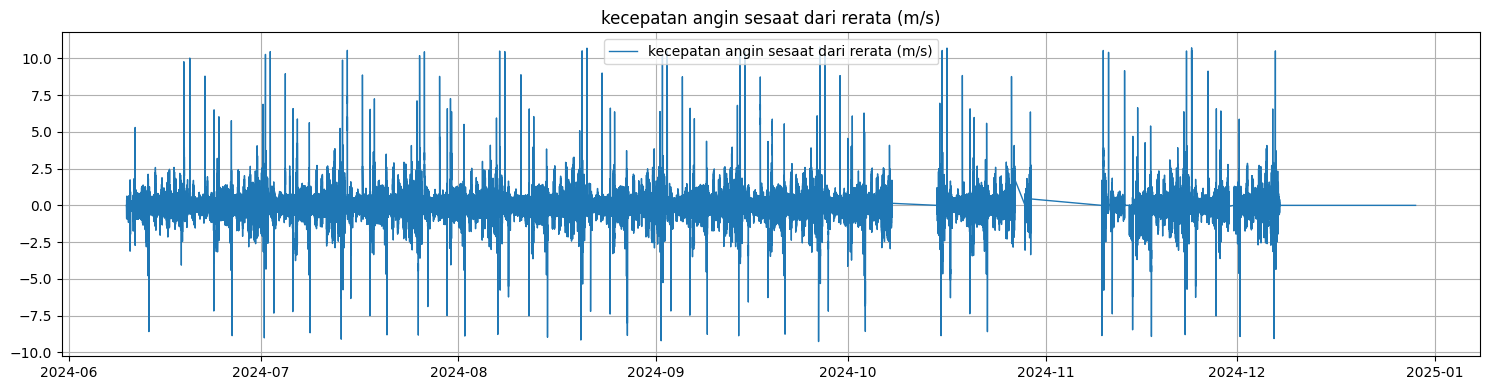

In [48]:
# Visualisasi hasil
plt.figure(figsize=(15, 4))
plt.plot(flux_c02['w_aksen'], label='kecepatan angin sesaat dari rerata (m/s)', linewidth=1)
plt.title("kecepatan angin sesaat dari rerata (m/s)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Mencari nilai dry mole fraction sesaat dari rerata (CO2dry')

C:\Users\USER\AppData\Local\Temp\ipykernel_21892\1140364977.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([flux_c02['co2']], labels=['co2'])


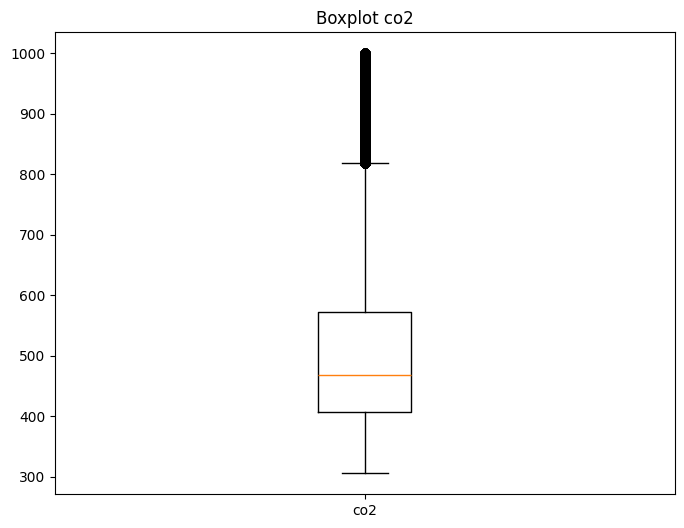

In [16]:
#Melihat Outlier pada data CO2 stasiun 1
plt.figure(figsize=(8, 6))
plt.boxplot([flux_c02['co2']], labels=['co2'])
plt.title('Boxplot co2')
plt.show()

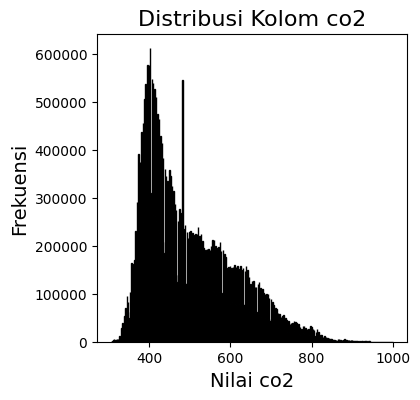

In [17]:
#Melihat distribusi data
# Membuat histogram distribusi kolom 'co2' 
plt.figure(figsize=(4, 4))
plt.hist(flux_c02['co2'], bins=500, color='skyblue', edgecolor='black')

# Menambahkan judul dan label
plt.title('Distribusi Kolom co2', fontsize=16)
plt.xlabel('Nilai co2', fontsize=14)
plt.ylabel('Frekuensi', fontsize=14)

# Menampilkan grafik
plt.show()

C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


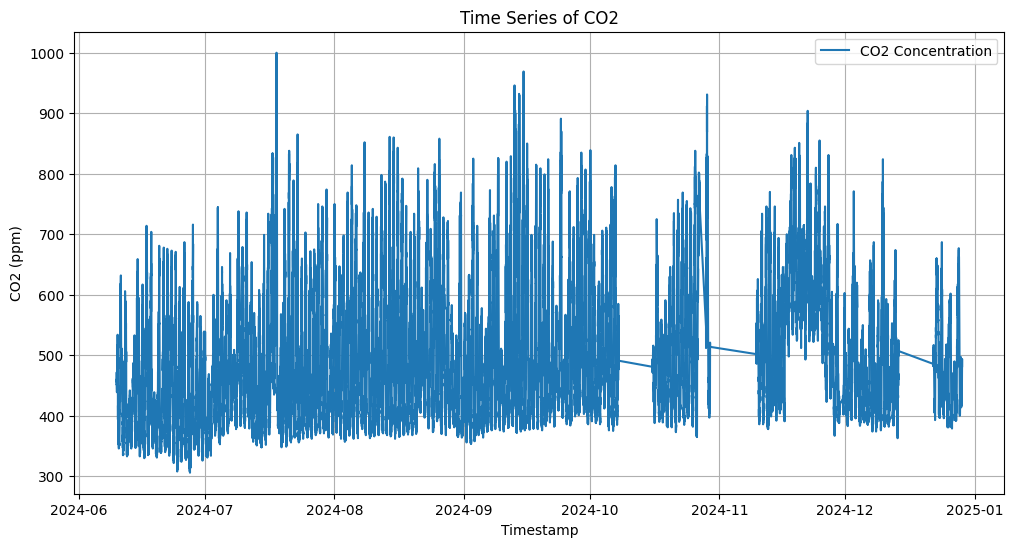

In [18]:
# Visualisasi sederhana
plt.figure(figsize=(12, 6))
plt.plot(flux_c02.index, flux_c02['co2'], label='CO2 Concentration')
plt.title('Time Series of CO2')
plt.xlabel('Timestamp')
plt.ylabel('CO2 (ppm)')
plt.legend()
plt.grid()
plt.show()

mencari Dry Mole Fraction

In [49]:
# Fungsi untuk menghitung tekanan uap jenuh (kPa)
def calc_p_H2O_sat(sht85Temp):
    return 0.61094 * np.exp((17.625 * sht85Temp ) / (sht85Temp + 243.04))

# Perhitungan Tekanan Uap Jenuh
flux_c02['p_H2O_sat'] = calc_p_H2O_sat(flux_c02['sht85Temp'])

# Mengubah nilai kelembapan relatif dari persentase ke bentuk desimal
flux_c02['RH_decimal'] = flux_c02['sht85Humi'] / 100

# Menghitung tekanan parsial uap air
flux_c02['p_H2O'] = flux_c02['RH_decimal'] * flux_c02['p_H2O_sat']

# Perhitungan Fraksi Mol Uap Air
flux_c02['x_H2O'] = flux_c02['p_H2O'] / flux_c02['bmp388Pressure']




In [50]:

# Perhitungan Fraksi Mol Udara Kering CO2
flux_c02['co2_dry'] = (flux_c02['co2']) / (1 - flux_c02['x_H2O'])

In [51]:
# hitung rata-rata rolling setiap 30 menit pada kolom co2_dry
flux_c02.loc[:, 'co2_dry_30m'] = flux_c02['co2_dry'].rolling('30T').mean()

C:\Users\USER\AppData\Local\Temp\ipykernel_11112\1412021551.py:2: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  flux_c02.loc[:, 'co2_dry_30m'] = flux_c02['co2_dry'].rolling('30T').mean()


In [52]:
#Mendapatkan nilai CO2dry sesaat dari rerata
flux_c02.loc[:, 'co2_dry_aksen'] = flux_c02['co2_dry'] - flux_c02['co2_dry_30m']

Mencari Nilai Flux Ecosystem(Fec)

In [53]:
# Mencari nilai tekanan udara kering terlebih dahulu
flux_c02['dry_pressure'] = flux_c02['bmp388Pressure'] - flux_c02['p_H2O']


# definiisikan nilai R (Konstanta gas ideal)
R = 8.314  # Konstanta gas ideal dalam J/(mol·K)

# Menghitung hasil dan membalikkan langsung
flux_c02['Fec'] = (flux_c02['w_aksen'] * flux_c02['co2_dry_aksen']) * (1 / (R * flux_c02['sht85Temp'] / flux_c02['dry_pressure']))



C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


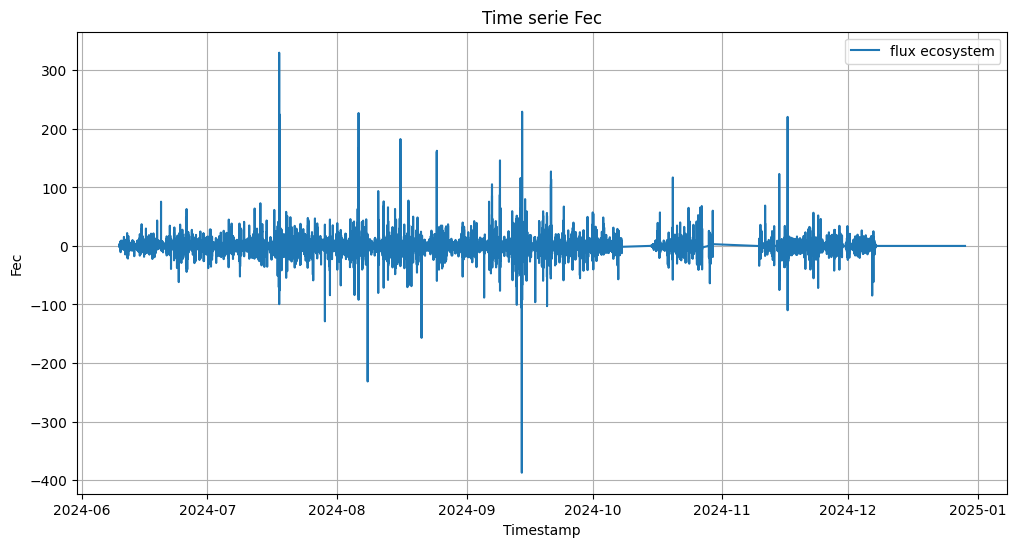

In [54]:
# Visualisasi sederhana
plt.figure(figsize=(12, 6))
plt.plot(flux_c02.index, flux_c02['Fec'], label='flux ecosystem')
plt.title('Time serie Fec')
plt.xlabel('Timestamp')
plt.ylabel('Fec')
plt.legend()
plt.grid()
plt.show()

VISULISASIKAN VARIABEL RUMUS_1

MEMBUANG OUTLIER 

In [58]:
# Membuat salinan DataFrame asli
flux_c02_z = flux_c02.copy()

In [59]:
# Contoh kolom yang akan dibersihkan dari outlier
target_col = 'Fec'  # ganti sesuai kebutuhan

# Hitung Z-score
z_scores = np.abs(stats.zscore(flux_c02_z[target_col], nan_policy='omit'))

# Threshold Z-score (misal: >3 dianggap outlier)
threshold = 6

# Filter data yang Z-score-nya di bawah threshold
df_clean = flux_c02_z[z_scores < threshold]

C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


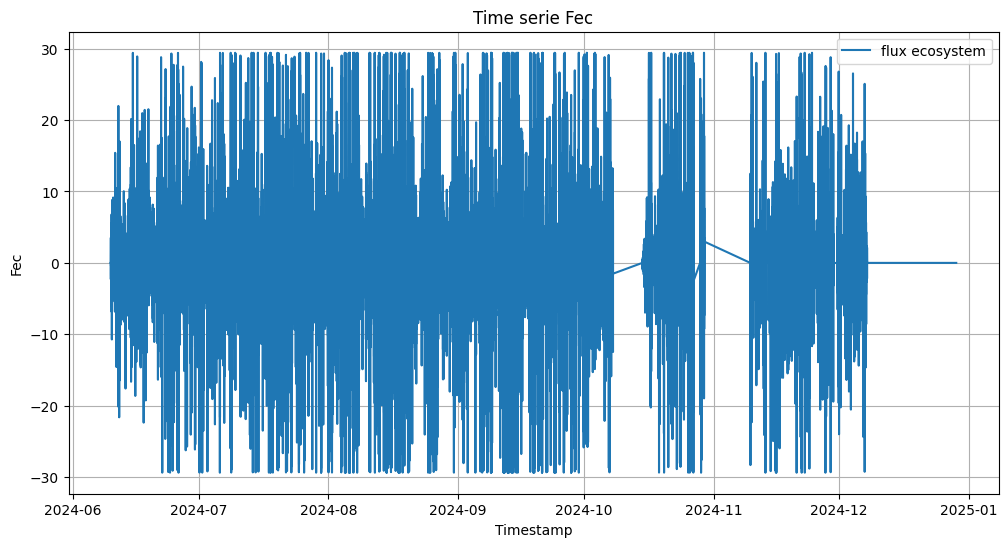

In [60]:
# Visualisasi sederhana
plt.figure(figsize=(12, 6))
plt.plot(df_clean.index, df_clean['Fec'], label='flux ecosystem')
plt.title('Time serie Fec')
plt.xlabel('Timestamp')
plt.ylabel('Fec')
plt.legend()
plt.grid()
plt.show()

In [61]:
nan_per_column = df_clean.isna().sum()
print("Jumlah nilai NaN per kolom:")
print(nan_per_column)

Jumlah nilai NaN per kolom:
bmp388Pressure    0
sht85Humi         0
sht85Temp         0
co2               0
bawah             0
atas              0
w                 0
w_30m             0
w_aksen           0
p_H2O_sat         0
RH_decimal        0
p_H2O             0
x_H2O             0
co2_dry           0
co2_dry_30m       0
co2_dry_aksen     0
dry_pressure      0
Fec               0
dtype: int64


In [62]:
#resample Fec menjadi per detik
flux_c02_detik = df_clean.resample('1S').mean()
print (flux_c02_detik)


C:\Users\USER\AppData\Local\Temp\ipykernel_11112\1859199339.py:2: FutureWarning: 'S' is deprecated and will be removed in a future version, please use 's' instead.
  flux_c02_detik = df_clean.resample('1S').mean()


                     bmp388Pressure  sht85Humi  sht85Temp         co2  \
timestamp                                                               
2024-06-10 00:06:01       94.939728  93.432518  25.907911  457.000000   
2024-06-10 00:06:02       99.238525  93.438876  25.907020  457.000000   
2024-06-10 00:06:03       98.883162  93.424126  25.911472  457.000000   
2024-06-10 00:06:04       99.118097  93.453880  25.930165  457.000000   
2024-06-10 00:06:05       99.003197  93.415951  25.910198  457.714286   
...                             ...        ...        ...         ...   
2024-12-28 23:35:56      103.156187  91.313577  23.385341  481.833333   
2024-12-28 23:35:57      103.033775  91.169591  23.395577  481.000000   
2024-12-28 23:35:58      103.205147  91.081292  23.388456  481.000000   
2024-12-28 23:35:59      103.039773  90.973436  23.387566  481.000000   
2024-12-28 23:36:00      102.985393  90.848570  23.393225  481.142857   

                        bawah      atas         w 

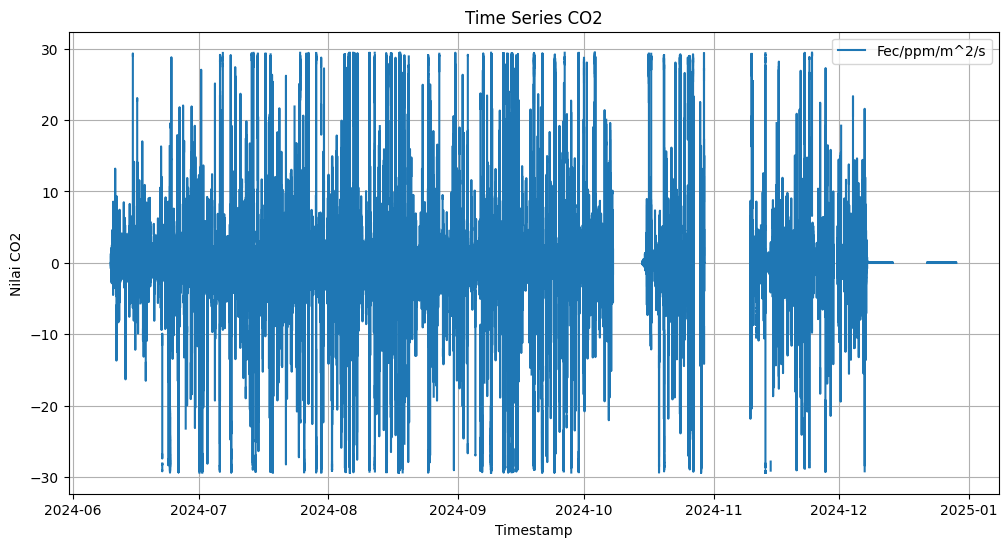

In [63]:
plt.figure(figsize=(12, 6))
plt.plot(flux_c02_detik.index,flux_c02_detik['Fec'], label="Fec/ppm/m^2/s")
plt.title('Time Series CO2')
plt.xlabel('Timestamp')
plt.ylabel('Nilai CO2')
plt.legend()
plt.grid()
plt.show()

In [64]:
flux_c02_detik.to_csv('Fec_perdetik.csv')

Mencari F_storage

In [3]:
flux_c02_detik = pd.read_csv("Fec_perdetik.csv")

In [4]:
co2_st1_detik = pd.read_csv("co2_st1.csv")

In [35]:
# Mengonversi kolom 'timestamp' ke datetime
flux_c02['timestamp'] = pd.to_datetime(flux_c02['timestamp'])

# Menjadikan 'timestamp' sebagai indeks
flux_c02.set_index('timestamp', inplace=True)

In [14]:
# Tanggal batas bawah
start_date = '2024-06-10 00:06:01'

# Hapus semua data sebelum tanggal tersebut
co2_st1_detik =co2_st1_detik.loc[co2_st1_detik.index >= start_date]

In [16]:
# Ganti semua nilai di bawah 250 menjadi NaN
co2_st1_detik['co2_st1'] = co2_st1_detik['co2_st1'].mask(co2_st1_detik['co2_st1'] < 250)


C:\Users\USER\AppData\Local\Temp\ipykernel_11112\3184224794.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  co2_st1_detik['co2_st1'] = co2_st1_detik['co2_st1'].mask(co2_st1_detik['co2_st1'] < 250)


In [28]:
co2_st1_detik.loc['2024-06-19 21:55':'2024-06-19 22:05', 'co2_st1'] = np.nan

C:\Users\USER\AppData\Local\Temp\ipykernel_11112\159673378.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  co2_st1_detik.loc['2024-06-19 21:55':'2024-06-19 22:05', 'co2_st1'] = np.nan


In [68]:
nan_per_column = co2_st1_detik.isna().sum()
print("Jumlah nilai NaN per kolom:")
print(nan_per_column)

Jumlah nilai NaN per kolom:
co2_st1    0
dtype: int64


In [ ]:
# Interpolasi time-based pada kolom co2_st1
co2_st1_detik['co2_st1'] = co2_st1_detik['co2_st1'].interpolate(method='time')


C:\Users\USER\AppData\Local\Temp\ipykernel_11112\423617680.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  co2_st1_detik['co2_st1'] = co2_st1_detik['co2_st1'].interpolate(method='time')


In [91]:
co2_st1_detik.to_csv('st1_perdetik.csv')

In [71]:
flux_c02_detik.head()

,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w,w_30m,w_aksen,p_H2O_sat,RH_decimal,p_H2O,x_H2O,co2_dry,co2_dry_30m,co2_dry_aksen,dry_pressure,Fec
timestamp,,,,,,,,,,,,,,,,,,
2024-06-10 00:06:01,94.939728,93.432518,25.907911,457.000000,0.025559,0.000000,-0.025559,-0.017209,-0.008350,3.336997,0.934325,3.117843,0.033156,472.677872,473.764525,-1.086653,91.821885,0.006358
2024-06-10 00:06:02,99.238525,93.438876,25.907020,457.000000,0.079437,0.046667,-0.032771,-0.002278,-0.030493,3.336820,0.934389,3.117888,0.031418,471.823902,472.342324,-0.518422,96.120637,0.002544
2024-06-10 00:06:03,98.883162,93.424126,25.911472,457.000000,0.016418,0.000000,-0.016418,-0.029582,0.013164,3.337698,0.934241,3.118216,0.031535,471.880556,472.133926,-0.253371,95.764946,-0.000982
2024-06-10 00:06:04,99.118097,93.453880,25.930165,457.000000,0.020834,0.000000,-0.020834,-0.022998,0.002164,3.341399,0.934539,3.122667,0.031505,471.866002,472.058647,-0.192645,95.995429,-0.000030
2024-06-10 00:06:05,99.003197,93.415951,25.910198,457.714286,0.162485,0.000000,-0.162485,-0.044941,-0.117544,3.337445,0.934160,3.117706,0.031491,472.596863,472.088477,0.508386,95.885491,-0.024127


In [72]:
# Menggabungkan flux_c02_detik dan co2_st1 berdasarkan kolom timestamp  
flux_sto = pd.merge(flux_c02_detik, co2_st1_detik, on='timestamp', how='left')  
  
# Menampilkan hasil  
print(flux_sto)

                     bmp388Pressure  sht85Humi  sht85Temp         co2  \
timestamp                                                               
2024-06-10 00:06:01       94.939728  93.432518  25.907911  457.000000   
2024-06-10 00:06:02       99.238525  93.438876  25.907020  457.000000   
2024-06-10 00:06:03       98.883162  93.424126  25.911472  457.000000   
2024-06-10 00:06:04       99.118097  93.453880  25.930165  457.000000   
2024-06-10 00:06:05       99.003197  93.415951  25.910198  457.714286   
...                             ...        ...        ...         ...   
2024-12-28 23:35:56      103.156187  91.313577  23.385341  481.833333   
2024-12-28 23:35:57      103.033775  91.169591  23.395577  481.000000   
2024-12-28 23:35:58      103.205147  91.081292  23.388456  481.000000   
2024-12-28 23:35:59      103.039773  90.973436  23.387566  481.000000   
2024-12-28 23:36:00      102.985393  90.848570  23.393225  481.142857   

                        bawah      atas         w 

In [73]:
flux_sto

,bmp388Pressure,sht85Humi,sht85Temp,co2,bawah,atas,w,w_30m,w_aksen,p_H2O_sat,RH_decimal,p_H2O,x_H2O,co2_dry,co2_dry_30m,co2_dry_aksen,dry_pressure,Fec,co2_st1
timestamp,,,,,,,,,,,,,,,,,,,
2024-06-10 00:06:01,94.939728,93.432518,25.907911,457.000000,0.025559,0.000000,-0.025559,-0.017209,-0.008350,3.336997,0.934325,3.117843,0.033156,472.677872,473.764525,-1.086653,91.821885,0.006358,560.0
2024-06-10 00:06:02,99.238525,93.438876,25.907020,457.000000,0.079437,0.046667,-0.032771,-0.002278,-0.030493,3.336820,0.934389,3.117888,0.031418,471.823902,472.342324,-0.518422,96.120637,0.002544,560.0
2024-06-10 00:06:03,98.883162,93.424126,25.911472,457.000000,0.016418,0.000000,-0.016418,-0.029582,0.013164,3.337698,0.934241,3.118216,0.031535,471.880556,472.133926,-0.253371,95.764946,-0.000982,560.0
2024-06-10 00:06:04,99.118097,93.453880,25.930165,457.000000,0.020834,0.000000,-0.020834,-0.022998,0.002164,3.341399,0.934539,3.122667,0.031505,471.866002,472.058647,-0.192645,95.995429,-0.000030,560.0
2024-06-10 00:06:05,99.003197,93.415951,25.910198,457.714286,0.162485,0.000000,-0.162485,-0.044941,-0.117544,3.337445,0.934160,3.117706,0.031491,472.596863,472.088477,0.508386,95.885491,-0.024127,560.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-28 23:35:56,103.156187,91.313577,23.385341,481.833333,9.570899,0.370000,-9.570899,-9.570899,0.000000,2.869881,0.913136,2.620596,0.025404,494.393097,494.977277,-0.584180,100.535591,0.000000,NaN
2024-12-28 23:35:57,103.033775,91.169591,23.395577,481.000000,9.570899,0.278333,-9.570899,-9.570899,0.000000,2.871649,0.911696,2.618070,0.025410,493.540860,494.976645,-1.435785,100.415705,0.000000,NaN
2024-12-28 23:35:58,103.205147,91.081292,23.388456,481.000000,9.570899,0.280000,-9.570899,-9.570899,0.000000,2.870415,0.910813,2.614412,0.025333,493.501724,494.975851,-1.474127,100.590735,0.000000,NaN


In [75]:
#ganti nama kolom
flux_sto = flux_sto.rename(columns={
    'co2': 'co2_st_2',
    'co2_st1': 'co2_st_1'
})



In [76]:
flux_sto.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 17451000 entries, 2024-06-10 00:06:01 to 2024-12-28 23:36:00
Data columns (total 19 columns):
 #   Column          Dtype  
---  ------          -----  
 0   bmp388Pressure  float64
 1   sht85Humi       float64
 2   sht85Temp       float64
 3   co2_st_2        float64
 4   bawah           float64
 5   atas            float64
 6   w               float64
 7   w_30m           float64
 8   w_aksen         float64
 9   p_H2O_sat       float64
 10  RH_decimal      float64
 11  p_H2O           float64
 12  x_H2O           float64
 13  co2_dry         float64
 14  co2_dry_30m     float64
 15  co2_dry_aksen   float64
 16  dry_pressure    float64
 17  Fec             float64
 18  co2_st_1        float64
dtypes: float64(19)
memory usage: 2.6 GB


In [78]:
# Ketinggian sensor (meter)
z = [3, 16]  # Ketinggian untuk st1, dan st2

# Hitung perubahan stok gas: dCO2/dt
# diff() menghitung perubahan antar baris
dt = 30 * 60  # 30 menit dalam detik
flux_sto['dco2_st1'] = flux_sto['co2_st_1'].diff() / dt
flux_sto['dco2_st2'] = flux_sto['co2_st_2'].diff() / dt


# Hitung integral perubahan stok gas menggunakan metode trapezoidal
def integrate_stock_change(dco2_dt_values, z):
    return np.trapz(dco2_dt_values, z)

flux_sto['flux_sto'] = flux_sto.apply(
    lambda row: integrate_stock_change(
        [row['dco2_st1'], row['dco2_st2']],
        z
    ), axis=1
)



In [79]:

# Hitung flux ecosystem
flux_sto['F_ecosystem'] = flux_sto['Fec'] + flux_sto['flux_sto']

# Hasil akhir
print(flux_sto)

                     bmp388Pressure  sht85Humi  sht85Temp    co2_st_2  \
timestamp                                                               
2024-06-10 00:06:01       94.939728  93.432518  25.907911  457.000000   
2024-06-10 00:06:02       99.238525  93.438876  25.907020  457.000000   
2024-06-10 00:06:03       98.883162  93.424126  25.911472  457.000000   
2024-06-10 00:06:04       99.118097  93.453880  25.930165  457.000000   
2024-06-10 00:06:05       99.003197  93.415951  25.910198  457.714286   
...                             ...        ...        ...         ...   
2024-12-28 23:35:56      103.156187  91.313577  23.385341  481.833333   
2024-12-28 23:35:57      103.033775  91.169591  23.395577  481.000000   
2024-12-28 23:35:58      103.205147  91.081292  23.388456  481.000000   
2024-12-28 23:35:59      103.039773  90.973436  23.387566  481.000000   
2024-12-28 23:36:00      102.985393  90.848570  23.393225  481.142857   

                        bawah      atas         w 

In [80]:
flux_sto

,bmp388Pressure,sht85Humi,sht85Temp,co2_st_2,bawah,atas,w,w_30m,w_aksen,p_H2O_sat,...,co2_dry,co2_dry_30m,co2_dry_aksen,dry_pressure,Fec,co2_st_1,dco2_st1,dco2_st2,flux_sto,F_ecosystem
timestamp,,,,,,,,,,,,,,,,,,,,,
2024-06-10 00:06:01,94.939728,93.432518,25.907911,457.000000,0.025559,0.000000,-0.025559,-0.017209,-0.008350,3.336997,...,472.677872,473.764525,-1.086653,91.821885,0.006358,560.0,NaN,NaN,NaN,NaN
2024-06-10 00:06:02,99.238525,93.438876,25.907020,457.000000,0.079437,0.046667,-0.032771,-0.002278,-0.030493,3.336820,...,471.823902,472.342324,-0.518422,96.120637,0.002544,560.0,0.0,0.000000,0.000000,0.002544
2024-06-10 00:06:03,98.883162,93.424126,25.911472,457.000000,0.016418,0.000000,-0.016418,-0.029582,0.013164,3.337698,...,471.880556,472.133926,-0.253371,95.764946,-0.000982,560.0,0.0,0.000000,0.000000,-0.000982
2024-06-10 00:06:04,99.118097,93.453880,25.930165,457.000000,0.020834,0.000000,-0.020834,-0.022998,0.002164,3.341399,...,471.866002,472.058647,-0.192645,95.995429,-0.000030,560.0,0.0,0.000000,0.000000,-0.000030
2024-06-10 00:06:05,99.003197,93.415951,25.910198,457.714286,0.162485,0.000000,-0.162485,-0.044941,-0.117544,3.337445,...,472.596863,472.088477,0.508386,95.885491,-0.024127,560.0,0.0,0.000397,0.002579,-0.021547
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-28 23:35:56,103.156187,91.313577,23.385341,481.833333,9.570899,0.370000,-9.570899,-9.570899,0.000000,2.869881,...,494.393097,494.977277,-0.584180,100.535591,0.000000,NaN,NaN,0.000370,NaN,NaN
2024-12-28 23:35:57,103.033775,91.169591,23.395577,481.000000,9.570899,0.278333,-9.570899,-9.570899,0.000000,2.871649,...,493.540860,494.976645,-1.435785,100.415705,0.000000,NaN,NaN,-0.000463,NaN,NaN
2024-12-28 23:35:58,103.205147,91.081292,23.388456,481.000000,9.570899,0.280000,-9.570899,-9.570899,0.000000,2.870415,...,493.501724,494.975851,-1.474127,100.590735,0.000000,NaN,NaN,0.000000,NaN,NaN


In [81]:
flux_sto.drop(columns={'dco2_st1','dco2_st2'}, inplace=True)

convert ke berat


In [82]:

tonase = 10 ** -6 #gram ke ton 10^-6
minggu = 52 # 52 minggu dalam 1 tahun
hektar = 10000 # 1 hektar 10,000 meter per segi

In [86]:
jumlah_NEE = flux_sto ['F_ecosystem'].sum() #flux ecosystem (ppm)
massa_co2 = 44.01 #gram per mol
suhu = flux_sto ['sht85Temp'].mean() # satuan C
T = suhu + 273.15
tekanan = flux_sto ['bmp388Pressure'].mean() #tekanan (kilopascal)
P = tekanan * 1000
R = 8.314 #konstanta gas ideal
n = 1000000 #konsentrasi seluruh gas diudara

#perhitungan 
hasil = (jumlah_NEE*massa_co2)/((n*R*T)/P)  
hasil = int(hasil)
print (f"NEE dalam ecosystem = {hasil} gram/m^3")

NEE dalam ecosystem = 23 gram/m^3


In [98]:
# Jika timestamp sudah jadi index datetime
df_sebelum_oktober = flux_sto[flux_sto.index.month < 10]


In [100]:
jumlah_NEE = df_sebelum_oktober ['F_ecosystem'].sum() #flux ecosystem (ppm)
massa_co2 = 44.01 #gram per mol
suhu = df_sebelum_oktober ['sht85Temp'].mean() # satuan C
T = suhu + 273.15
tekanan = df_sebelum_oktober ['bmp388Pressure'].mean() #tekanan (kilopascal)
P = tekanan * 1000
R = 8.314 #konstanta gas ideal
n = 1000000 #konsentrasi seluruh gas diudara

#perhitungan 
hasil = (jumlah_NEE*massa_co2)/((n*R*T)/P)  
hasil = int(hasil)
print (f"NEE dalam ecosystem = {hasil} gram/m^3")

NEE dalam ecosystem = 55 gram/m^3


In [88]:
# Hitung jumlah F_ecosystem positif dan negatif
jumlah_positif = int(flux_sto[flux_sto['F_ecosystem'] > 0]['F_ecosystem'].sum())
jumlah_negatif = int(flux_sto[flux_sto['F_ecosystem'] < 0]['F_ecosystem'].sum())

gramasi_1 = int((jumlah_positif*massa_co2)/((n*R*T)/P))
gramasi_2 = int((jumlah_negatif*massa_co2)/((n*R*T)/P))

print(f"Jumlah pelepasan co2 oleh ekosistem: {jumlah_positif} ppm atau {gramasi_1} g/m^3")
print(f"Jumlah penyerapan co2 oleh ekosistem: {jumlah_negatif} pm atau {gramasi_2} g/m^3")

Jumlah pelepasan co2 oleh ekosistem: 3730855 ppm atau 6645 g/m^3
Jumlah penyerapan co2 oleh ekosistem: -3717534 pm atau -6621 g/m^3


In [89]:
#simpan hasil data
flux_sto.to_csv('F_ecosytem.csv')




In [8]:
flux_sto['F_ecosystem'].describe()

count    298708.000000
mean          0.204832
std           1.558423
min         -12.508799
25%          -0.115702
50%           0.012757
75%           0.283527
max          12.871649
Name: F_ecosystem, dtype: float64

C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


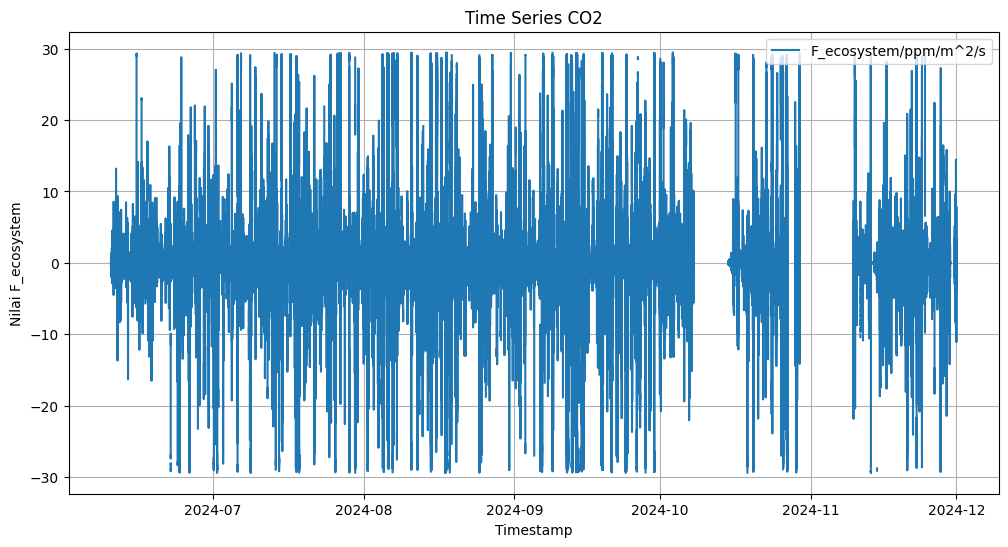

In [90]:
plt.figure(figsize=(12, 6))
plt.plot(flux_sto.index,flux_sto['F_ecosystem'], label="F_ecosystem/ppm/m^2/s")
plt.title('Time Series CO2')
plt.xlabel('Timestamp')
plt.ylabel('Nilai F_ecosystem')
plt.legend()
plt.grid()
plt.show()

In [6]:
df1 = pd.read_csv('F_ecosytem.csv')

In [7]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17451000 entries, 0 to 17450999
Data columns (total 22 columns):
 #   Column          Dtype  
---  ------          -----  
 0   timestamp       object 
 1   bmp388Pressure  float64
 2   sht85Humi       float64
 3   sht85Temp       float64
 4   co2_st_2        float64
 5   bawah           float64
 6   atas            float64
 7   w               float64
 8   w_30m           float64
 9   w_aksen         float64
 10  p_H2O_sat       float64
 11  RH_decimal      float64
 12  p_H2O           float64
 13  x_H2O           float64
 14  co2_dry         float64
 15  co2_dry_30m     float64
 16  co2_dry_aksen   float64
 17  dry_pressure    float64
 18  Fec             float64
 19  co2_st_1        float64
 20  flux_sto        float64
 21  F_ecosystem     float64
dtypes: float64(21), object(1)
memory usage: 2.9+ GB


In [11]:
bulanan = df1[['timestamp','F_ecosystem']].copy()

In [12]:
bulanan

,timestamp,F_ecosystem
0,2024-06-10 00:06:01,NaN
1,2024-06-10 00:06:02,0.002544
2,2024-06-10 00:06:03,-0.000982
3,2024-06-10 00:06:04,-0.000030
4,2024-06-10 00:06:05,-0.021547
...,...,...
17450995,2024-12-28 23:35:56,NaN
17450996,2024-12-28 23:35:57,NaN
17450997,2024-12-28 23:35:58,NaN
17450998,2024-12-28 23:35:59,NaN


In [ ]:
# Pastikan timestamp dalam format datetime
bulanan['timestamp'] = pd.to_datetime(bulanan['timestamp'])

# Set sebagai index untuk resampling
bulanan.set_index('timestamp', inplace=True)

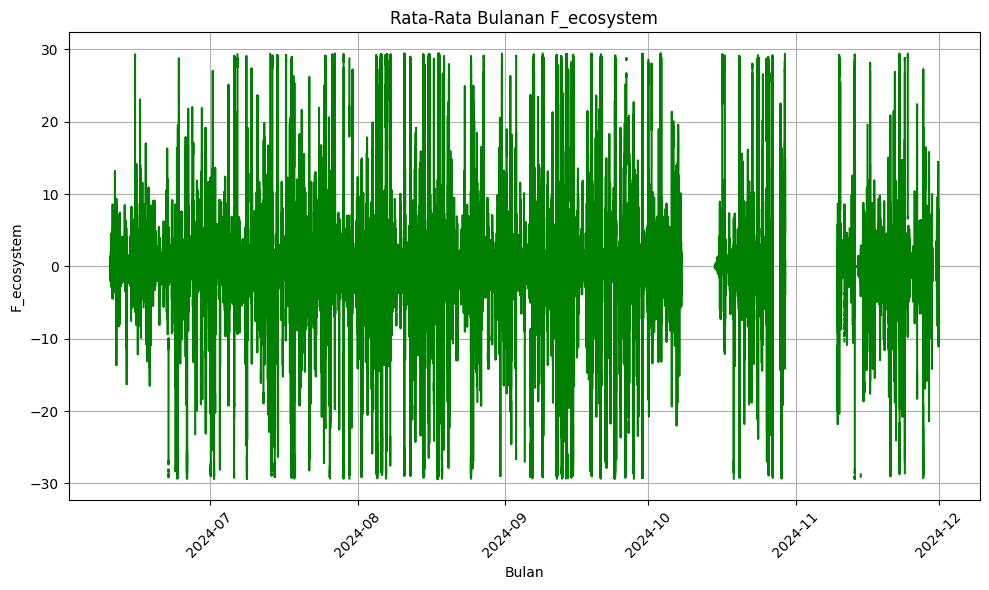

In [15]:

# Plot
plt.figure(figsize=(10, 6))
plt.plot(bulanan.index, bulanan.values, linestyle='-', color='green')
plt.title('Rata-Rata Bulanan F_ecosystem')
plt.xlabel('Bulan')
plt.ylabel('F_ecosystem')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
data = bulanan.copy()

In [17]:
data = data.dropna()

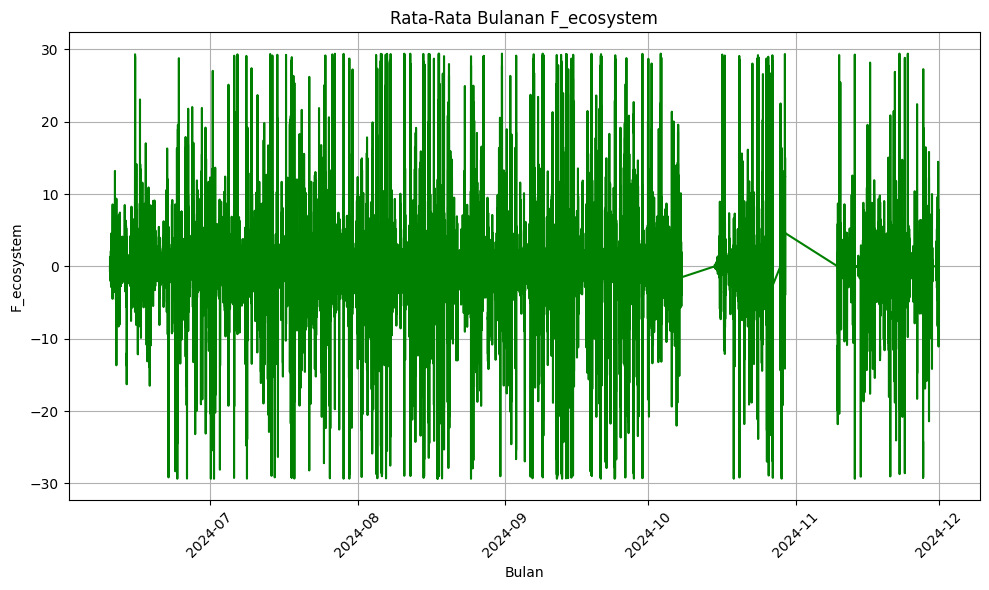

In [18]:
# Plot
plt.figure(figsize=(10, 6))
plt.plot(data.index, data.values, linestyle='-', color='green')
plt.title('Rata-Rata Bulanan F_ecosystem')
plt.xlabel('Bulan')
plt.ylabel('F_ecosystem')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_8700\2981978280.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  emisi_bulanan = data[data['F_ecosystem'] > 0].resample('M').sum()['F_ecosystem']
C:\Users\USER\AppData\Local\Temp\ipykernel_8700\2981978280.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  serapan_bulanan = data[data['F_ecosystem'] < 0].resample('M').sum()['F_ecosystem']


              Emisi (CO₂)  Serapan (CO₂)
timestamp                               
2024-06-30  433043.661481  336811.624405
2024-07-31  712061.765293  715469.335384
2024-08-31  835052.881896  846448.592739
2024-09-30  891601.728480  941733.187279
2024-10-31  495056.586799  485426.416940
2024-11-30  364039.298724  391644.991191


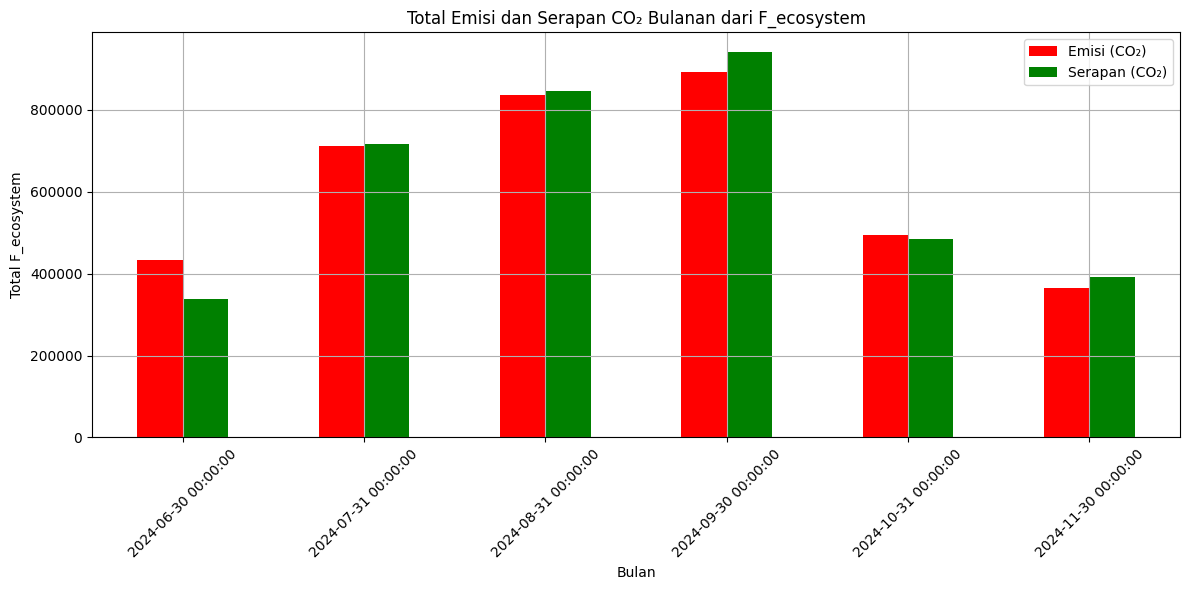

In [19]:
# Filter nilai positif (emisi) dan negatif (serapan)
emisi_bulanan = data[data['F_ecosystem'] > 0].resample('M').sum()['F_ecosystem']
serapan_bulanan = data[data['F_ecosystem'] < 0].resample('M').sum()['F_ecosystem']

# Gabungkan menjadi satu DataFrame
df_bulanan = pd.DataFrame({
    'Emisi (CO₂)': emisi_bulanan,
    'Serapan (CO₂)': serapan_bulanan
})

# Konversi nilai serapan ke nilai positif agar mudah dibandingkan secara visual
df_bulanan['Serapan (CO₂)'] = df_bulanan['Serapan (CO₂)'].abs()

# Tampilkan data
print(df_bulanan)

# Visualisasi
df_bulanan.plot(kind='bar', figsize=(12, 6), color=['red', 'green'])
plt.title('Total Emisi dan Serapan CO₂ Bulanan dari F_ecosystem')
plt.xlabel('Bulan')
plt.ylabel('Total F_ecosystem')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.legend(loc='upper right')
plt.show()

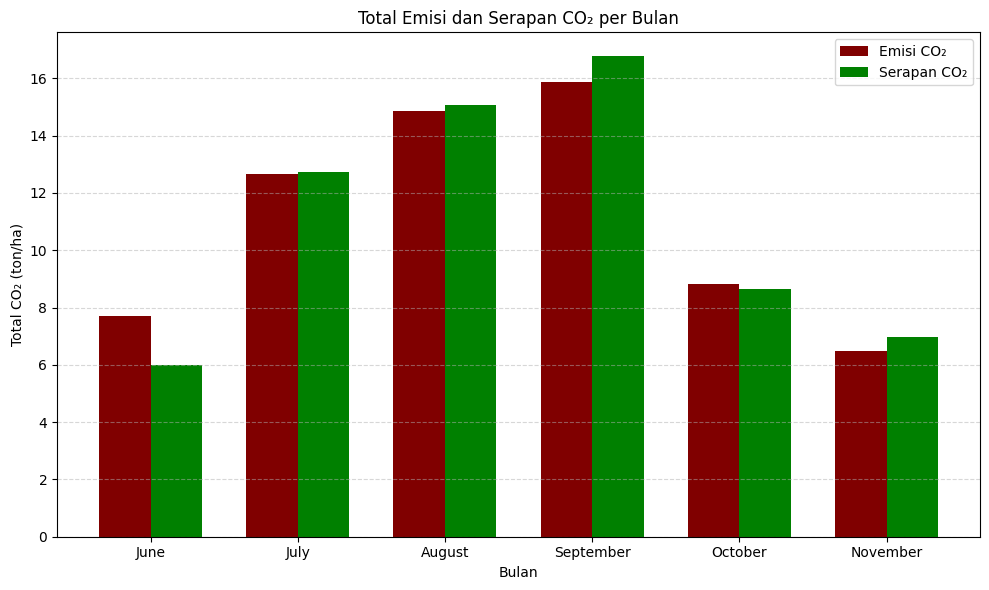

In [52]:
# Plot bar
plt.figure(figsize=(10, 6))
bar_width = 0.35
x = range(len(df_bulanan))

# Bar untuk emisi dan serapan
plt.bar(x, df_bulanan['emisi_gram'], width=bar_width, label='Emisi CO₂ ', color='maroon')
plt.bar([i + bar_width for i in x], df_bulanan['serapan_gram'], width=bar_width, label='Serapan CO₂', color='green')

# Label dan judul
plt.xlabel('Bulan')
plt.ylabel('Total CO₂ (ton/ha)')
plt.title('Total Emisi dan Serapan CO₂ per Bulan')
plt.xticks([i + bar_width / 2 for i in x], df_bulanan['Bulan'], rotation=0)
plt.legend()
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [54]:
df_bulanan


,Emisi (CO₂),Serapan (CO₂),emisi_gram,serapan_gram,Bulan,NEE (ton)
timestamp,,,,,,
2024-06-30,433043,433043,7.71,6.00,June,1.71
2024-07-31,712061,712061,12.68,12.74,July,-0.06
2024-08-31,835052,835052,14.87,15.07,August,-0.20
2024-09-30,891601,891601,15.88,16.77,September,-0.89
2024-10-31,495056,495056,8.82,8.64,October,0.18
2024-11-30,364039,364039,6.48,6.97,November,-0.49


In [53]:
df_bulanan['NEE (ton)'] = df_bulanan['emisi_gram'] - df_bulanan['serapan_gram']


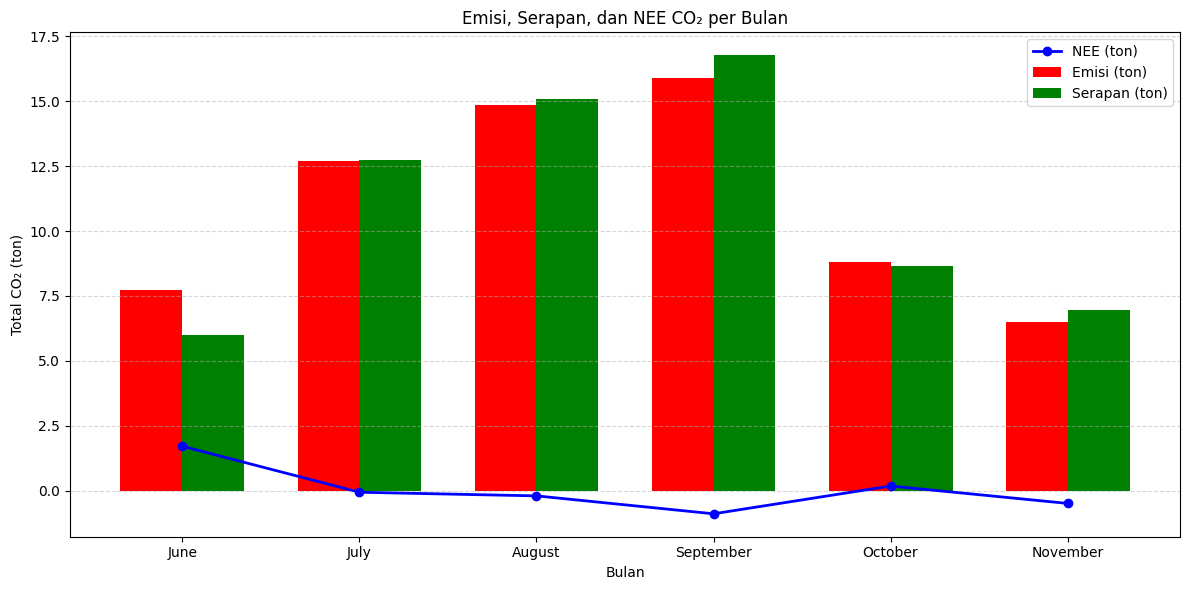

In [55]:


# Data dan sumbu X
bulan = df_bulanan['Bulan']
x = range(len(bulan))
bar_width = 0.35

# Buat plot
plt.figure(figsize=(12, 6))

# Bar plot untuk Emisi dan Serapan
plt.bar(x, df_bulanan['emisi_gram'], width=bar_width, label='Emisi (ton)', color='red')
plt.bar([i + bar_width for i in x], df_bulanan['serapan_gram'], width=bar_width, label='Serapan (ton)', color='green')

# Garis plot untuk NEE
plt.plot([i + bar_width / 2 for i in x], df_bulanan['NEE (ton)'], label='NEE (ton)', color='blue', marker='o', linewidth=2)

# Label dan tata letak
plt.xticks([i + bar_width / 2 for i in x], bulan)
plt.xlabel('Bulan')
plt.ylabel('Total CO₂ (ton)')
plt.title('Emisi, Serapan, dan NEE CO₂ per Bulan')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


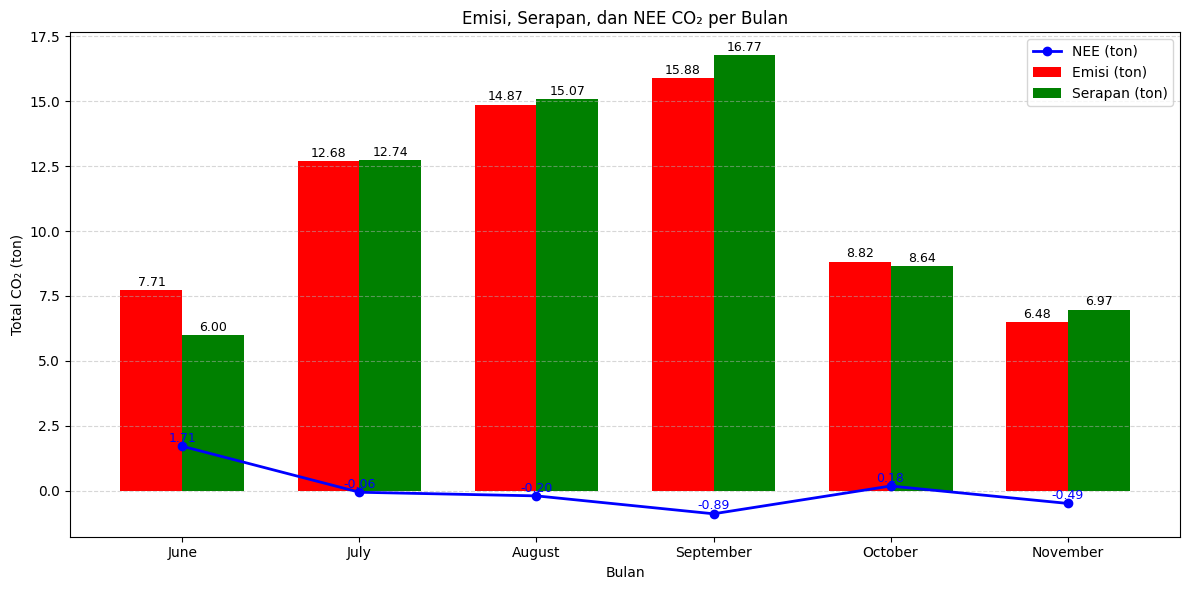

In [58]:
import matplotlib.pyplot as plt

# Data dan sumbu X
bulan = df_bulanan['Bulan']
x = range(len(bulan))
bar_width = 0.35

plt.figure(figsize=(12, 6))

# Bar plot untuk Emisi dan Serapan
bar1 = plt.bar(x, df_bulanan['emisi_gram'], width=bar_width, label='Emisi (ton)', color='red')
bar2 = plt.bar([i + bar_width for i in x], df_bulanan['serapan_gram'], width=bar_width, label='Serapan (ton)', color='green')

# Garis plot untuk NEE
nee_x = [i + bar_width / 2 for i in x]
nee_y = df_bulanan['NEE (ton)']
plt.plot(nee_x, nee_y, label='NEE (ton)', color='blue', marker='o', linewidth=2)

# Tambah label angka di atas bar dan titik
for i in x:
    # Emisi
    plt.text(i, df_bulanan['emisi_gram'].iloc[i] + 0.05, f"{df_bulanan['emisi_gram'].iloc[i]:.2f}", 
             ha='center', va='bottom', fontsize=9, color='black')
    # Serapan
    plt.text(i + bar_width, df_bulanan['serapan_gram'].iloc[i] + 0.05, f"{df_bulanan['serapan_gram'].iloc[i]:.2f}", 
             ha='center', va='bottom', fontsize=9, color='black')
    # NEE
    plt.text(nee_x[i], nee_y.iloc[i] + 0.05, f"{nee_y.iloc[i]:.2f}",
             ha='center', va='bottom', fontsize=9, color='blue')

# Label dan tata letak
plt.xticks([i + bar_width / 2 for i in x], bulan)
plt.xlabel('Bulan')
plt.ylabel('Total CO₂ (ton)')
plt.title('Emisi, Serapan, dan NEE CO₂ per Bulan')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [42]:
df_bulanan['emisi_gram'] = (df_bulanan['Emisi (CO₂)'] * convert).round(2)
df_bulanan['serapan_gram'] = (df_bulanan['Serapan (CO₂)'] * convert).round(2)

In [44]:
df_bulanan['Emisi (CO₂)'] = df_bulanan['Emisi (CO₂)'].astype(int)
df_bulanan['Serapan (CO₂)'] = df_bulanan['Emisi (CO₂)'].astype(int)

In [46]:
df_bulanan['Bulan'] = df_bulanan.index.strftime('%B')

In [48]:
df_bulanan['emisi_gram'].sum()

66.44

In [49]:
df_bulanan['serapan_gram'].sum()

66.19

In [40]:

massa_co2 = 44.01 #gram per mol
suhu = df ['sht85Temp'].mean() # satuan C
T = suhu + 273.15
tekanan = df ['bmp388Pressure'].mean() #tekanan (kilopascal)
P = tekanan * 1000
R = 8.314 #konstanta gas ideal
n = 1000000 #konsentrasi seluruh gas diudara
l = 10000 # luas hektar = 10000m^2
ton = 1000000 #gram ke ton bagi dengan 1.000.000

convert = (P*l*massa_co2)/(n*R*T*ton)
print (convert)

1.7808972732249014e-05


In [41]:
print (total * convert)

66.44271139484972


In [28]:
suhu = df ['sht85Temp'].mean() # satuan C
print (suhu)

26.89751057239525


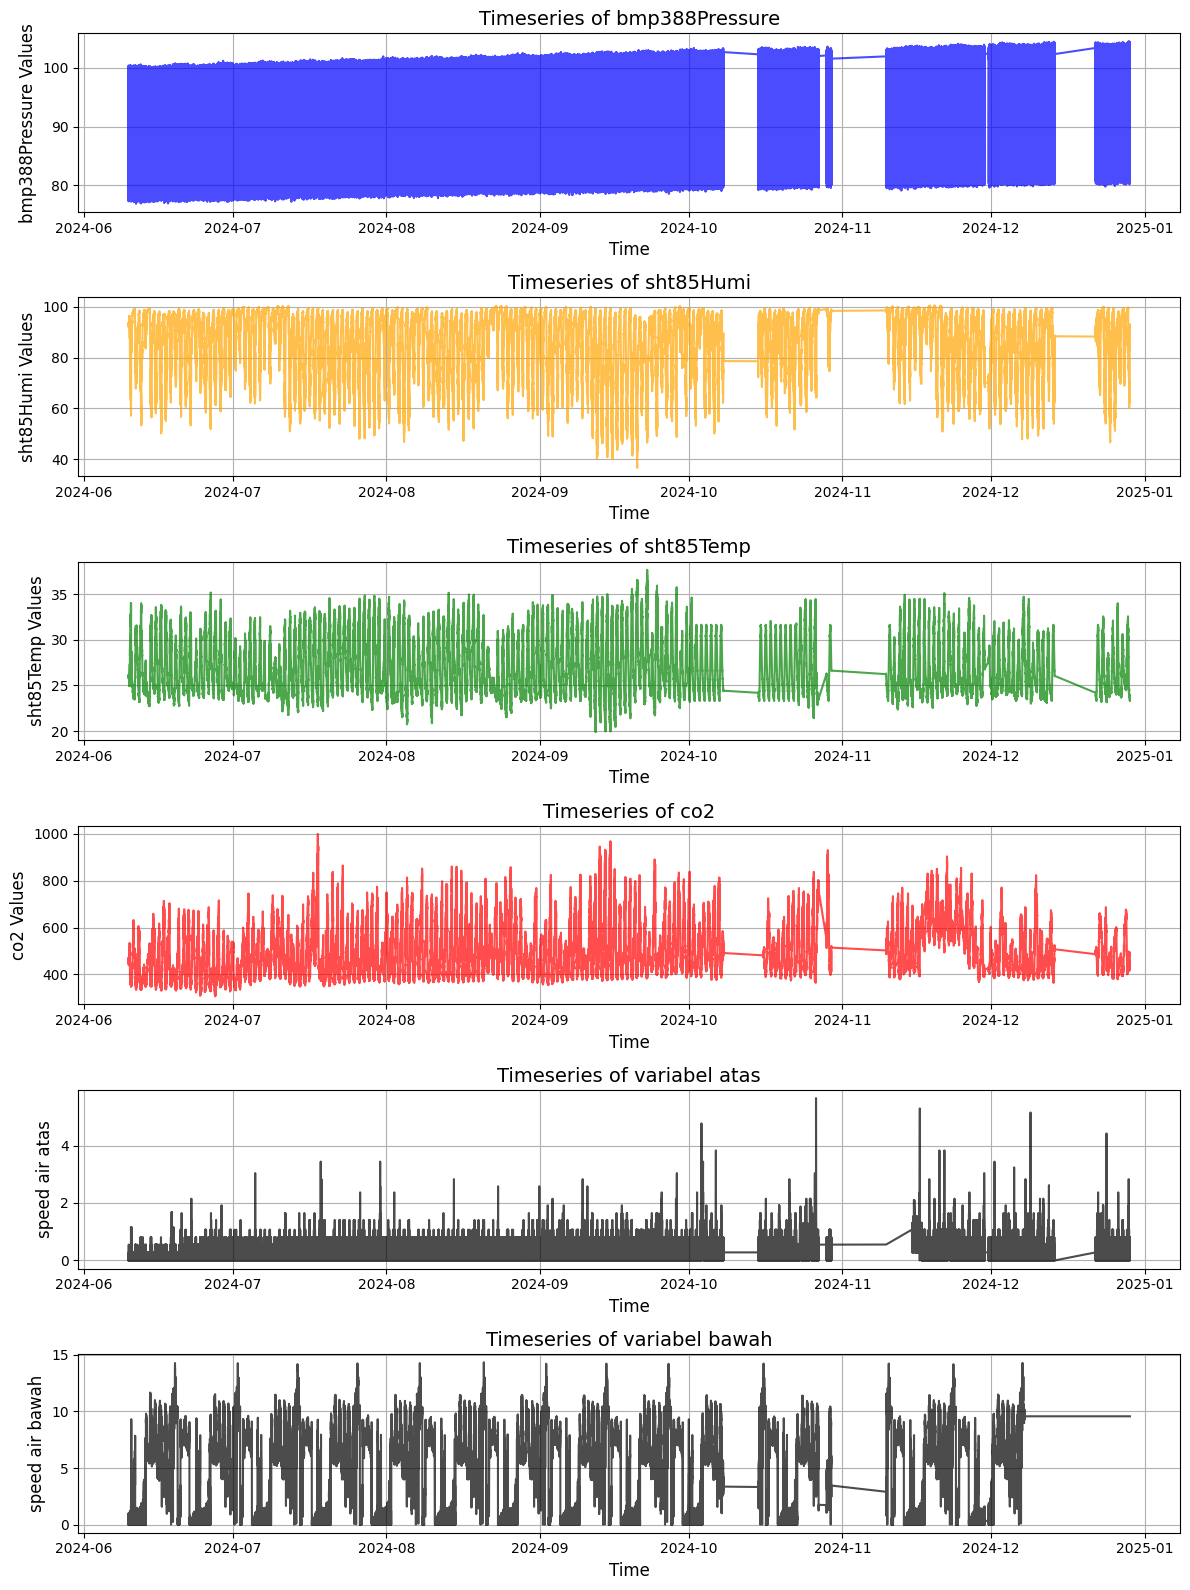

In [27]:
plt.figure(figsize=(12,16))

plt.subplot(6, 1, 1)  # (jumlah baris, jumlah kolom, indeks subplot)
plt.plot(df.index, df['bmp388Pressure'], label='bmp388Pressure', color='blue', alpha=0.7)
plt.title('Timeseries of bmp388Pressure', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('bmp388Pressure Values', fontsize=12)
plt.grid(True)


plt.subplot(6, 1, 2)
plt.plot(df.index, df['sht85Humi'], label='sht85Humi', color='orange', alpha=0.7)
plt.title('Timeseries of sht85Humi', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('sht85Humi Values', fontsize=12)
plt.grid(True)


plt.subplot(6, 1, 3)
plt.plot(df.index, df['sht85Temp'], label='sht85Temp', color='green', alpha=0.7)
plt.title('Timeseries of sht85Temp', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('sht85Temp Values', fontsize=12)
plt.grid(True)


plt.subplot(6, 1, 4)
plt.plot(df.index, df['co2'], label='co2', color='r', alpha=0.7)
plt.title('Timeseries of co2', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('co2 Values', fontsize=12)
plt.grid(True)


plt.subplot(6, 1, 5)
plt.plot(df.index, df['atas'], label='atas', color='black', alpha=0.7)
plt.title('Timeseries of variabel atas', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air atas', fontsize=12)
plt.grid(True)


plt.subplot(6, 1, 6)
plt.plot(df.index, df['bawah'], label='bawah', color='black', alpha=0.7)
plt.title('Timeseries of variabel bawah', fontsize=14)
plt.xlabel('Time', fontsize=12)
plt.ylabel('speed air bawah', fontsize=12)
plt.grid(True)
# Adjust layout for better spacing
plt.tight_layout()

# Tampilkan plot
plt.show()